# **Análisis de reseñas de Nequi: *Sentimiento, temas e insights***
Este notebook toma la base cruda construida en `01_recoleccion_datos` (34.328 reseñas de Google Play, nov-2025 a nov-2026) y la convierte en insights y estrategias de negocio. El archivo crudo nunca se modifica: toda la transformación ocurre en memoria y los resultados se guardan en carpetas separadas.

# 0 - Configuración
## Instalación y Drive

In [ ]:
# Librerías que Colab no trae: Modelo de sentimiento en español y manejo de emojis
! pip install -q pysentimiento==0.7.3 emoji==2.16.0

# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0.2 - Importaciones globales

In [ ]:
# Utilidades estándar
import re, hashlib, random, warnings, unicodedata
from collections import Counter
from pathlib import Path

# Datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Texto y emojis
import nltk
from nltk.corpus import stopwords
import emoji
from wordcloud import WordCloud

# Modelos
import torch
import joblib
from pysentimiento import create_analyzer # Sentimiento en español (RoBERTuito)
from sentence_transformers import SentenceTransformer # Embeddings para el clustering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA
from difflib import get_close_matches   # Busca palabras parecidas (glosario ortográfico)

warnings.filterwarnings('ignore')
nltk.download("stopwords", quiet = True)

True

## 0.3 - Parámetros generales

In [ ]:
# Reproducibilidad
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# Rutas (El archivo crudo solo es de lectura, las salidas van a carpetas a parte)
RUTA_PROYECTO = Path("/content/drive/MyDrive/Colab Notebooks/No supervisado/Workshops/Final - Reseñas Usuarios Nequi")
ARCHIVO_DATOS = RUTA_PROYECTO / "data" / "raw" / "nequi_reseñas_raw.xlsx"
DIR_PROCESADOS = RUTA_PROYECTO / "data" / "procesados"
DIR_FIGURAS = RUTA_PROYECTO / "reportes" / "figuras"
DIR_SALIDAS = RUTA_PROYECTO / "salidas"
DIR_MODELOS = RUTA_PROYECTO / "modelos"

for carpeta in [DIR_PROCESADOS, DIR_FIGURAS, DIR_SALIDAS, DIR_MODELOS]:
  carpeta.mkdir(parents = True, exist_ok = True)

# Paletas aptas para daltonismo (cada categoría tiene un color fijo)
COLORES_SENTIMIENTO = {"Negativo": "#D55E00", "Neutral": "#9E9E9E", "Positivo": "#0072B2"}
ORDEN_SENTIMIENTO   = list(COLORES_SENTIMIENTO)
COLORES_CLUSTER     = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#000000"]  # Okabe-Ito sin amarillo
COLOR_BASE          = "#56B4E9"   # gráficos de una sola serie
CMAP_SECUENCIAL     = "Blues"     # conteos y porcentajes
CMAP_DIVERGENTE     = "RdBu"      # valores con signo (correlaciones, polaridad)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# Dispositivo: GPU si está disponible (acelera sentimiento y embeddings)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DISPOSITIVO)

def guardar_figura(fig, nombre, modulo):
    """Guarda la figura en PNG con prefijo de módulo (ej. 03_serie_mensual.png)."""
    ruta = DIR_FIGURAS / f"{modulo:02d}_{nombre}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    return ruta

Dispositivo: cpu


## 0.4 - Huella del archivo original (MD5)
### El MD5 es una "huella digital" del archivo: si cambia un solo byte, cambia la huella. Se calcula al inicio y al final para demostrar que el archivo crudo nunca se modificó.

In [ ]:
def md5_archivo (ruta):
    """Devuelve el hash MD5 de un archivo, leyéndolo por bloques"""
    h = hashlib.md5()
    with open (ruta, "rb") as f:
      for bloque in iter (lambda : f.read(8192), b""):
        h.update(bloque)
    return h.hexdigest()

MD5_ORIGINAL = md5_archivo (ARCHIVO_DATOS)
print("MD5 original:", MD5_ORIGINAL)

MD5 original: 5dad937bad0de1ed21d09ba9e8cb87e3


# 1 - Caso de negocio, recolección y carga

## **Caso de negocio**
### ¿Por qué Nequi?
- **Relevancia:** Nequi alcanzó **28 millones de usuarios** en mayo de 2026, en su décimo aniversario. Es una de las plataformas financieras más usadas de Colombia.
- **Momento estratégico:** En 2026 Nequi se separó de Bancolombia y opera como compañía de financiamiento independiente. Su reputación ya no se apoya en la del banco: depende de su propia experiencia de usuario.
- **Señales de alerta:** Durante Diciembre de 2025 la app sufrió caídas repetidas asociadas a su migración a la nube, y la prensa reporta fallas recurrentes en días de quincena.

## Pregunta de negocio
> **¿Qué problemas dañan la experiencia de los usuarios de Nequi; cómo cambian en el tiempo y qué acciones debe priorizar la compañía para proteger su reputación en su nueva etapa independiente?**

Preguntas de apoyo:
1. ¿Qué sentimiento predomina y qué tan confiable es su medición automática?
2. ¿Qué temas concentran las quejas y cuáles generan valoración positiva?
3. ¿Qué temas representan riesgo reputacional o intención de abandono?
4. ¿Cómo responde Nequi a las reseñas de sus usuarios?

### Fuente
Reseñas públicas de la app **Nequi Colombia** en **Google Play**: la tienda donde el usuario califica la app justo después de usarla. Cada reseña trae texto, estrellas, votos de utilidad, versión de la app y la respuesta oficial de Nequi.

### Decisiones que podría tomar la empresa
El análisis busca informar decisiones en cinco áreas. Para cada una planteamos una **hipótesis inicial**, basada en contexto público, que el análisis confirmará o descartará:

| Área | Tipo de decisión | Hipótesis inicial (a validar) |
|---|---|---|
| Tecnología | Dónde invertir en estabilidad de la plataforma | Las caídas en días de alta demanda concentran las quejas (fuente: prensa) |
| Servicio al cliente | Cómo rediseñar la atención de quejas | Los canales de soporte no resuelven y generan frustración |
| Producto | Qué funciones corregir primero | Algunas funciones específicas generan más fricción que otras |
| Comunicación | Cómo comunicar durante una crisis | La falta de información durante las caídas amplifica el daño reputacional |
| Marca | Qué atributos potenciar | Existen atributos valorados que pueden reforzar la lealtad |

> Las hipótesis se revisan en el módulo 10 con la evidencia obtenida.

## 1.2 - **Proceso de recolección**
La base se construyó en el notebook `01_recoleccion_datos`, porque no existe una base de datos pública de reseñas de Nequi.

| Decisión | Detalle |
| --- | --- |
| Herramientas | `google-play-scraper` 1.2.7 (sin API key) |
| Filtros | Tienda de Colombia, idioma español |
| Ventana | 12 meses: 04/11/2025 - 03/11/2026 |
| Tamaño | 34.328 reseñas (~94 por día) |
| Privacidad | Sin nombres ni fotos de usuarios |

**Limitaciones:** Solo usuarios de Android OS; las reseñas son autoseleccionadas (escribe más quien está muy satisfecho o muy molesto); `fecha` corresponde a la última edición de la reseña, no a la original.

## Dataset

| Atributo | Detalle |
|---|---|
| **Archivo** | `data/raw/nequi_reseñas_raw.xlsx` (solo lectura) |
| **Fuente** | Reseñas públicas de la app *Nequi Colombia* (`com.nequi.MobileApp`) en Google Play |
| **Recolección** | `google-play-scraper` 1.2.7, tienda de Colombia, idioma español, noviembre de 2026 (notebook `01_recoleccion_datos`) |
| **Periodo** | 04/11/2025 a 03/11/2026 (12 meses) |
| **Tamaño** | 34.328 reseñas × 9 columnas |
| **Privacidad** | No incluye nombres ni fotos de usuarios |

### Diccionario de datos
| Columna | Tipo | Descripción |
|---|---|---|
| `fuente` | texto | Origen de la reseña (siempre "Google Play") |
| `id_comentario` | texto | Identificador único de la reseña |
| `texto` | texto | Reseña tal como la escribió el usuario |
| `calificacion` | entero (1–5) | Estrellas otorgadas por el usuario |
| `me_gusta` | entero | Votos de "útil" que dieron otros usuarios |
| `fecha` | fecha y hora | Fecha de la **última edición** de la reseña (no la original) |
| `version_app` | texto | Versión de la app instalada al momento de reseñar |
| `respuesta_nequi` | texto | Respuesta oficial de Nequi (vacío = no respondió) |
| `fecha_respuesta` | fecha y hora | Fecha de la respuesta de Nequi |

## 1.3 - Carga de datos

In [ ]:
# El crudo queda intacto en df_crudo; todo el trabajo ocurre sobre la variable 'df'
df_crudo = pd.read_excel(ARCHIVO_DATOS)
df = df_crudo.copy()
print ("Forma:", df.shape)
df.head(3).T

Forma: (34328, 9)


,0,1,2
fuente,Google Play,Google Play,Google Play
id_comentario,ebb03a65-30a6-4102-a50e-06892cf07d2c,8223d084-6712-41c3-be3b-7a39121ccfba,da2acdc7-6111-45db-b769-cc54afec03c2
texto,exelente,exelente,excelente lo malo es que no tiene plata
calificacion,5,5,5
me_gusta,0,0,0
fecha,2026-11-03 21:06:22,2026-11-03 20:59:32,2026-11-03 20:48:43
version_app,7.1.2,7.1.2,7.1.3
respuesta_nequi,NaN,NaN,NaN
fecha_respuesta,NaT,NaT,NaT


## 1.4 - Diagnóstico de calidad de los datos

In [ ]:
def diagnosticar (datos):
    """Resumen de calidad por columna: tipo, nulos y cardinalidad (valores únicos)"""
    return pd.DataFrame({
        "tipo" : datos.dtypes.astype(str),
        "nulos" : datos.isna().sum(),
        "pct_nulos" : (datos.isna().mean() * 100).round(2),
        "unicos" : datos.nunique(),
    })

print("IDs duplicados:", df["id_comentario"].duplicated().sum())
print("Textos repetidos:", df["texto"].duplicated().sum())
print("Rangos de fechas:", df["fecha"].min().date(), "->", df["fecha"].max().date())

diagnosticar(df)

IDs duplicados: 0
Textos repetidos: 13330
Rangos de fechas: 2025-11-04 -> 2026-11-03


,tipo,nulos,pct_nulos,unicos
fuente,object,0,0.00,1
id_comentario,object,0,0.00,34328
texto,object,0,0.00,20998
calificacion,int64,0,0.00,5
me_gusta,int64,0,0.00,79
fecha,datetime64[ns],0,0.00,34294
version_app,object,3473,10.12,110
respuesta_nequi,object,8296,24.17,18282
fecha_respuesta,datetime64[ns],8296,24.17,26031


## 1.5 - Distribución de estrellas

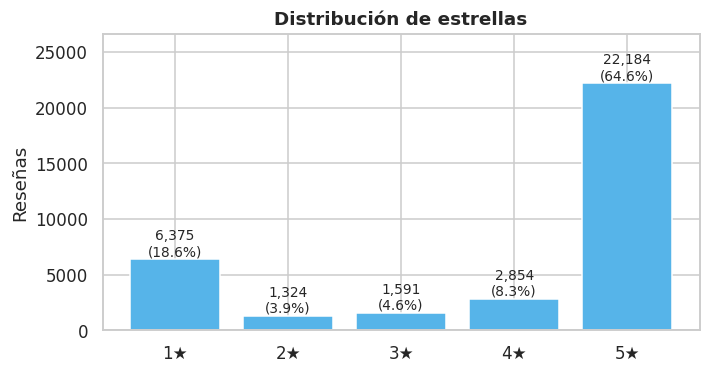

In [ ]:
# Conteo y porcentaje por estrella (Referencia valida para validar el sentimiento. Nunca para clasificarlo)
estrellas = df["calificacion"].value_counts().sort_index()
pct = estrellas / len(df) *100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(estrellas.index.astype(str) + "★", estrellas.values, color=COLOR_BASE)
for i, (n, p) in enumerate(zip(estrellas, pct)):
    ax.text(i, n, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de estrellas")
ax.set_ylabel("Reseñas")
ax.set_ylim(0, estrellas.max() * 1.2)
guardar_figura(fig, "distribucion_estrellas", modulo=1)
plt.show()

## 1.6 - **Hallazgos - Carga y diagnóstico**
- **34.328 reseñas sin IDs duplicados**, con 12 meses completos
- **13.330 textos repetidos:** Usualmente reseñas cortas como "muy bueno" o "excelente"
- **Distribución en J**: Observar gráfica en índice 1.5 (Distribución de estrellas)
- **Nulos:** `version_app` no se reporta en aproximadamente 10% de las reseñas.`respuesta_nequi` vacío en aproximadamente 24% de los casos (significa que Nequi no respondió). Ninguno de estos se imputa

# 2 - Limpieza y preparación de texto
*Idea central*: Creamos dos versiones del texto, una para cada uso. No se elimina ninguna reseña. Los casos especiales se **marcan con flags** y cada decisión tomada en el proceso de limpieza de texto queda en una bitácora

Se crean dos versiones del texto, porque cada técninca necesita una limpieza distinta:

`var`: 'texto_modelo'. Limpieza mínima (Conserva mayúsculas, puntuación y emojis). Se usa para implementar modelos como `pysentimiento` que entienden mayúsculas, signos y emojis. Limpiarlos les qutaría información y contexto.


`var`: `texto_limpio` / `tokens`. Limpieza profunda. Los conteos de palabras necesitan normalizar los textos a pesar de distinciones en cada uno (Mayúsculas, tildes o tipeos)

## 2.2 - Bitácora de limpieza

### Las celdas del módulo 2 NO son idempotentes. **Si algo falla: Correr de nuevo desde índice 1.3**

In [ ]:
# Bitácora: Cada decisión de limpieza quedará registrada allí.

bitacora = []

def registrar_paso (paso, problema, filas, decision, justificacion):
    """Agrega una decisión de limpieza a la bitárcora y muestra la cantidad de filas afectadas"""
    bitacora.append({
        "paso" : paso,
        "problema" : problema,
        "filas_afectadas" : int(filas),
        "decisión" : decision,
        "justificación" : justificacion
    })
    print(f"[{paso}] {problema} -> {int(filas):,} filas")

## 2.3 - Extracción de emojis
Se extraen **antes** de limpiar, porque la limpieza los borra. Los tonos de piel se normalizan para que cuenten como el mismo emoji.

In [ ]:
# Tonos de piel y selector de variación (FE0F) que hacen ver distinto el mismo emoji
PATRON_TONOS = re.compile (r"[\U0001F3FB-\U0001F3FF\uFE0F]")

def extraer_emojis(texto):
    """Devuelve los emojis del texto separados por espacio, sin tonos de piel"""
    return " ". join(PATRON_TONOS.sub("", e["emoji"]) for e in emoji.emoji_list(texto))

df["emojis"] = df["texto"].astype(str).apply(extraer_emojis)
df["n_emojis"] = df["emojis"].str.split().str.len()

registrar_paso("2.3", "Reseñas con emojis", (df["n_emojis"] > 0).sum(),
               "Extraer a la columna 'emojis' y normalizar tonos de piel",
               "La limpieza los borraría y cargan sentimiento (capa de emojis, módulo 5)")

[2.3] Reseñas con emojis -> 2,655 filas


## 2.4 - Normalización Unicode y texto para el modelo
Algunos usuarios escriben con fuentes decorativas. Para python no son letras, y la limpieza las borraría por completo...

La normalización **NFKC** las convierte a letras / caracteres normales

In [ ]:
# NFKC: Convierte las letras decorativas en letras normales
texto_nfkc = df["texto"].astype(str).apply(lambda t: unicodedata.normalize("NFKC", t))

registrar_paso("2.4", "Letras con fuentes decorativas", (texto_nfkc != df["texto"]).sum(),
               "Normalización Unicode NFKC", "Sin esto, la limpieza borraría reseñas completas")

# Texto para el modelo: Solo se unifican espacios; se conservan signosm mayúsculas y emojis
df["texto_modelo"] = texto_nfkc.str.replace(r"\s+", " ", regex=True).str.strip()

[2.4] Letras con fuentes decorativas -> 39 filas


## 2.5 - Texto limpio

| Paso | Ejemplo | Por qué |
|---|---|---|
| Minúsculas y sin tildes | "Fácil" -> "facil" | Los usuarios pueden incurrir en escribir la misma palabra con y sin tilde |
| Solo letras | "10/10!!" -> "" | Números y signos no aportan a los conteos |
| Letras repetidas | "noooo" -> "no" | Unifica la misma palabra escrita con énfasis |
| Glosario ortográfico | "exelente" -> "excelente" | Evita que un error divida los conteos de una palabra |

La **ñ** se conserva para exitar pérdidas de contexto en reseñas

**Cómo se construye el glosario:** se buscan palabras parecidas (≥ 80 % de similitud) a las 40 palabras más frecuentes, entre las que aparecen al menos 5 veces.

Luego se revisan a mano: **solo entran errores ortográficos**, no plurales ni conjugaciones ("buenas", "funcionar").

### 2.5a - Detección de variantes

In [ ]:
TILDES = str.maketrans("áéíóúü", "aeiouu")

# Texto base para buscar variantes: minúsculas, sin tildes, solo letras y sin letras repetidas
texto_min = df["texto_modelo"].str.lower()
sin_tildes = texto_min.str.translate(TILDES)
base = (sin_tildes.str.replace(r"[^a-zñ\s]", " ", regex=True)
                  .str.replace(r"([a-zñ])\1{2,}", r"\1", regex=True))

# Frecuencia de palabras y vocabulario mínimo (≥ 5 apariciones, para ignorar errores únicos)
conteo = Counter(" ".join(base).split())
vocabulario = [p for p, n in conteo.items() if n >= 5]
frecuentes = [p for p, _ in conteo.most_common() if len(p) >= 5][:40]   # 5+ letras: evita stopwords

# Para cada palabra frecuente, mostrar variantes parecidas y menos comunes (candidatas a error)
for palabra in frecuentes:
    variantes = [(v, conteo[v]) for v in get_close_matches(palabra, vocabulario, n=6, cutoff=0.8)
                 if v != palabra and conteo[v] < conteo[palabra]]
    if variantes:
        print(f"{palabra} ({conteo[palabra]:,}): {variantes}")

excelente (5,538): [('execelente', 75), ('excelentes', 37), ('exelente', 1527), ('ecelente', 8), ('exelentes', 6)]
buena (4,810): [('buenas', 292), ('buen', 450), ('bueno', 2374), ('biena', 5)]
aplicacion (4,238): [('plicacion', 7), ('aplicaciones', 87), ('aplicasion', 19), ('explicacion', 15), ('calificacion', 31)]
nequi (3,567): [('nequis', 27), ('nequ', 5)]
bueno (2,374): [('buenos', 123), ('buen', 450)]
dinero (1,788): [('dineros', 17), ('dieron', 34)]
mejor (1,621): [('mejoro', 15), ('mejore', 11), ('mejora', 20), ('mejores', 108), ('mejoren', 61)]
servicio (1,546): [('servicios', 227), ('servisio', 7), ('cervicio', 13), ('servicial', 11), ('servido', 52)]
exelente (1,527): [('exelentes', 6), ('ecxelente', 52), ('exlente', 11), ('exelete', 5)]
cuenta (1,501): [('cuentas', 89), ('cuesta', 8), ('cuento', 17), ('cuanta', 14), ('encuentra', 14)]
mucho (1,474): [('muchos', 198), ('mucha', 147)]
cuando (1,440): [('usando', 70), ('cuanto', 70), ('ando', 16)]
super (1,301): [('supera', 8)

### Glosario seleccionado
De los candidatos anteriores se conservan solo los errores ortográficos. Se descartan plurales, conjugaciones y palabras distintas que solo se parecen (ej. "facial" =! "facil", "hora" =! "ahora").

### 2.5b - Limpieza

In [ ]:
# Errores ortográficos elegidos de la celda anterior -> forma correcta
GLOSARIO = {
    "exelente": "excelente", "execelente": "excelente", "ecelente": "excelente", "ecxelente": "excelente",
    "exlente": "excelente", "exelete": "excelente", "exelentes": "excelentes",
    "aplicasion": "aplicacion", "plicacion": "aplicacion", "servisio": "servicio", "cervicio": "servicio",
    "fasil": "facil", "grasias": "gracias", "targeta": "tarjeta", "jenial": "genial",
    "habrir": "abrir", "dentrar": "entrar", "veses": "veces", "aveces": "a veces", "porq": "porque",
    "ap": "app",   # "appp" queda como "ap" tras quitar repeticiones
}

def limpiar_texto(texto):
    """Minúsculas, sin tildes, solo letras, sin letras repetidas y con ortografía corregida."""
    texto = texto.lower().translate(TILDES)
    texto = re.sub(r"[^a-zñ\s]", " ", texto)          # solo letras (conserva la ñ)
    texto = re.sub(r"([a-zñ])\1{2,}", r"\1", texto)   # 3+ letras iguales -> 1
    return " ".join(GLOSARIO.get(p, p) for p in texto.split())

# Conteos para la bitácora (antes de aplicar la limpieza)
patron_glosario = r"\b(?:" + "|".join(GLOSARIO) + r")\b"
registrar_paso("2.5b", "Tildes inconsistentes (fácil / facil)", texto_min.str.contains(r"[áéíóúü]").sum(),
               "Quitar tildes (se conserva la ñ)", "Unifica variantes de la misma palabra")
registrar_paso("2.5b", "Letras repetidas (noooo)", sin_tildes.str.contains(r"([a-zñ])\1{2,}").sum(),
               "Reducir 3+ letras iguales a 1", "El énfasis se conserva en texto_modelo")
registrar_paso("2.5b", "Errores ortográficos frecuentes", base.str.contains(patron_glosario).sum(),
               f"Glosario de {len(GLOSARIO)} variantes", "Sin corregir, un error divide los conteos de una palabra")
df["texto_limpio"] = df["texto_modelo"].apply(limpiar_texto)
df[["texto", "texto_limpio"]].sample(5, random_state=SEMILLA)

[2.5b] Tildes inconsistentes (fácil / facil) -> 12,393 filas
[2.5b] Letras repetidas (noooo) -> 218 filas
[2.5b] Errores ortográficos frecuentes -> 2,022 filas


,texto,texto_limpio
30544,LA PEOR APLICACIÓN QUE EXISTE PARA MANEJAR DIN...,la peor aplicacion que existe para manejar din...
24775,No están llegando las notificaciones,no estan llegando las notificaciones
23374,Las notificaciones no funcionan 🤷🏻🤦🏻,las notificaciones no funcionan
14107,exelente,excelente
31413,exelente,excelente


## 2.6 — Tokens y stopwords
Las *stopwords* son palabras sin contenido ("de", "la", "que"). Se eliminan para que los conteos muestren de qué se habla.
- **Se conservan las negaciones** ("no", "ni", "sin", "nunca"): "no me deja entrar" cambia por completo sin el "no".
- **Se eliminan palabras de la marca** ("nequi", "app", "aplicacion"): aparecen en casi todas las reseñas y no dicen nada sobre el tema.

In [ ]:
# Stopwords en español (sin tildes, igual  que el texto) menos las negaciones. Más palabras "de la marca"
# Quitamos lo que sobra (la marca) y conservamos lo que cambia el significado (las negaciones).
STOPWORDS = {p.translate(TILDES) for p in stopwords.words("spanish")} - {"no", "ni", "sin", "nunca"}
STOPWORDS |= {"nequi", "app", "aplicacion", "aplicaciones"}

def tokenizar (texto):
    """Palabras sin stopwords y de más de una letra, unidas por espacio (fáciles de exportar)"""
    return " ".join(p for p in texto.split() if p not in STOPWORDS and len(p) > 1)

df["tokens"] = df["texto_limpio"].apply(tokenizar)
todos_tokens = " ".join(df["tokens"]).split()

print(f"Tokens totales: {len(todos_tokens):,} | Vocabulario: {len(set(todos_tokens)):,}") # `set()` elimina los repetidos. Dando así el "Vocabulario"
# Vocabulario comprende las palabras únicas.

Tokens totales: 171,686 | Vocabulario: 11,052


## 2.7 — Flags y variables nuevas
| Variable | Significado |
|---|---|
| `n_palabras` | Palabras en `texto_limpio` |
| `flag_corta` | Menos de 4 palabras (**no entra al clustering**) |
| `flag_solo_emoji` | Solo emojis (la capa de emojis decide su sentimiento) |
| `flag_sin_texto` | Sin letras ni emojis (ej. "10/10") |
| `tiene_respuesta` | Nequi respondió la reseña |
| `flag_editada` | La respuesta es anterior a `fecha`: el usuario editó su reseña después |
| `version_menor` | Versión agrupada (7.1.3 → 7.1) |
| `horas_respuesta` | Horas entre la reseña y la respuesta de Nequi (solo respondidas y no editadas) |

In [ ]:
# Longitud y casos especiales
df["n_palabras"] = df["texto_limpio"].str.split().str.len()
df["flag_corta"] = (df["n_palabras"] < 4).astype(int)
df["flag_solo_emoji"] = ((df["n_palabras"] == 0) & (df["n_emojis"] > 0)).astype(int)
df["flag_sin_texto"] = ((df["n_palabras"] == 0) & (df["n_emojis"] == 0)).astype(int)
pct_positivas_cortas = df.loc[df["flag_corta"] == 1, "calificacion"].ge(4).mean() * 100

# Porcentaje de reseñas cortas con 4 o 5 estrellas (Justifica ser conservadas)
print(f"{pct_positivas_cortas:.1f} % de las reseñas con menos de 4 palabras, tienen valoraciones altas (4 o 5 estrellas)")

registrar_paso("2.7", "Reseñas cortas (<4 palabras)", df["flag_corta"].sum(), "Conservar + flag",
               f"{pct_positivas_cortas:.1f} % son de 4-5 estrellas: eliminarlas sesgaría el análisis")

registrar_paso("2.7","Reseñas solo con emojis", df["flag_solo_emoji"].sum(), "Conservar + flag",
               "Su sentimiento lo decide la capa de emojis netamente (Ver módulo 5)",)

registrar_paso("2.7", "Reseñas sin letras sin emojis", df["flag_sin_texto"].sum(), "Conservar + flag",
               "Se reportan como neutrales")

92.6 % de las reseñas con menos de 4 palabras, tienen valoraciones altas (4 o 5 estrellas)
[2.7] Reseñas cortas (<4 palabras) -> 16,979 filas
[2.7] Reseñas solo con emojis -> 372 filas
[2.7] Reseñas sin letras sin emojis -> 5 filas


### Respuestas de Nequi

In [ ]:
# Respuestas de Nequi
df["tiene_respuesta"] = df["respuesta_nequi"].notna().astype(int)
df["flag_editada"] = (df["fecha_respuesta"] < df["fecha"]).astype(int)

registrar_paso("2.7", "Respuesta anterior a la fecha de la reseña", df["flag_editada"].sum(), "Conservar + flag",
               "'fecha' es la última edición: se excluyen del cálculo de tiempo de respuesta")

# Tiempo de respuesta en horas: *solo reseñas respondidas y no editadas* (en ellas 'fecha' es la original):
respuesta_valida = (df["tiene_respuesta"] == 1) & (df["flag_editada"] == 0)
df["horas_respuesta"] = ((df["fecha_respuesta"] - df["fecha"]).dt.total_seconds() / 3600).where(respuesta_valida)
print(df["horas_respuesta"].describe().round(2))

[2.7] Respuesta anterior a la fecha de la reseña -> 252 filas
count    25780.00
mean         1.36
std          3.62
min          0.00
25%          0.07
50%          0.12
75%          0.25
max         37.42
Name: horas_respuesta, dtype: float64


### Versión de la app

In [ ]:
df["version_app"] = df["version_app"].fillna("Sin dato")
df["version_menor"] = df["version_app"].str.extract(r"^(\d+\.\d+)")[0].fillna("Sin dato")

registrar_paso("2.7", "Versión de la app vacía", df["version_app"].isna().sum(), "Imputar 'Sin dato'",
               "No se inventa una versión; solo se usa para describir")

print("\n Forma final:", df.shape)

[2.7] Versión de la app vacía -> 0 filas

 Forma final: (34328, 22)


## 2.8 - Exportación y resumen visual

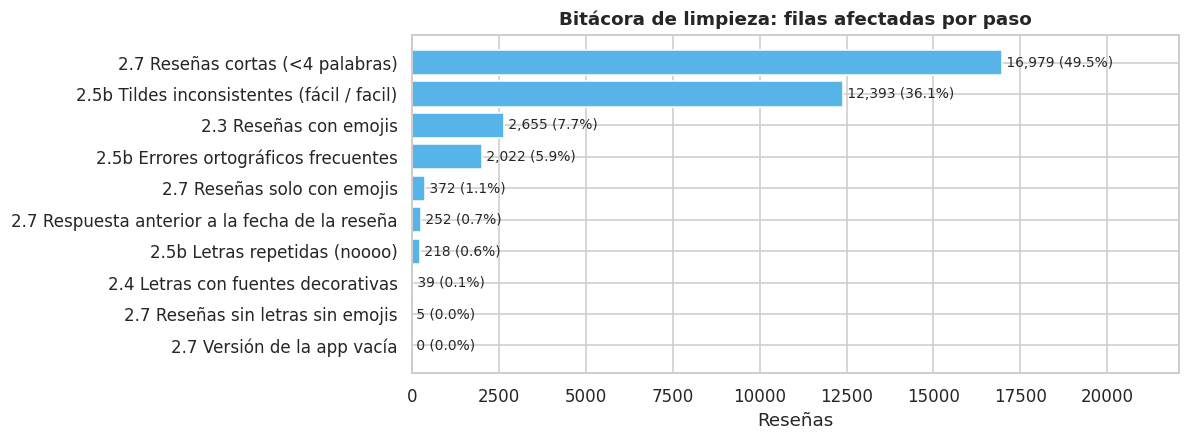

,paso,problema,filas_afectadas,decisión,justificación
0,2.3,Reseñas con emojis,2655,Extraer a la columna 'emojis' y normalizar ton...,La limpieza los borraría y cargan sentimiento ...
1,2.4,Letras con fuentes decorativas,39,Normalización Unicode NFKC,"Sin esto, la limpieza borraría reseñas completas"
2,2.5b,Tildes inconsistentes (fácil / facil),12393,Quitar tildes (se conserva la ñ),Unifica variantes de la misma palabra
3,2.5b,Letras repetidas (noooo),218,Reducir 3+ letras iguales a 1,El énfasis se conserva en texto_modelo
4,2.5b,Errores ortográficos frecuentes,2022,Glosario de 21 variantes,"Sin corregir, un error divide los conteos de u..."
5,2.7,Reseñas cortas (<4 palabras),16979,Conservar + flag,92.6 % son de 4-5 estrellas: eliminarlas sesga...
6,2.7,Reseñas solo con emojis,372,Conservar + flag,Su sentimiento lo decide la capa de emojis net...
7,2.7,Reseñas sin letras sin emojis,5,Conservar + flag,Se reportan como neutrales
8,2.7,Respuesta anterior a la fecha de la reseña,252,Conservar + flag,'fecha' es la última edición: se excluyen del ...
9,2.7,Versión de la app vacía,0,Imputar 'Sin dato',No se inventa una versión; solo se usa para de...


In [ ]:
# Exportar bitácora de limpieza + base limpia y editada
bitacora_df = pd.DataFrame(bitacora)
bitacora_df.to_excel(DIR_SALIDAS /"02_bitacora_limpieza.xlsx", index = False)
df.to_excel(DIR_PROCESADOS / "02_nequi_reseñas_limpias.xlsx", index = False)

# Gráfico: filas afectadas por paso (paso + problema como etiqueta única)
datos = bitacora_df.sort_values("filas_afectadas")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(datos["paso"] + " " + datos["problema"], datos["filas_afectadas"], color=COLOR_BASE)
for i, n in enumerate(datos["filas_afectadas"]):
    ax.text(n, i, f" {n:,} ({n / len(df):.1%})", va="center", fontsize=9)
ax.set_title("Bitácora de limpieza: filas afectadas por paso")
ax.set_xlabel("Reseñas")
ax.set_xlim(0, datos["filas_afectadas"].max() * 1.3)
guardar_figura(fig, "bitacora_limpieza", modulo=2)
plt.show()

bitacora_df

## 2.9 - **Hallazgos - Limpieza**
- **No se eliminó ninguna reseña** con 10 decisiones registradas en la bitácora.
- **Dos versiones del texto:** `texto_modelo` (mínima, para modelos de lenguaje) y `texto_limpio` (profunda, para conteos).
- **Reseñas cortas:** 16.979 tiene menos de 4 palabras; de ellas, 92.6% son de 4-5 estrellas.
- **Glosario:** corrige 2.022 reseñas con errores ortográficos frecuentes.

**Cómo afectan estas decisiones a los resultados:**
| Decisión | Efecto |
|---|---|
| Conservar reseñas cortas | Mantiene la proporción real de opiniones positivas |
| Conservar negaciones | Evita leer "no funciona" como "funciona" |
| Quitar palabras de la marca | Las nubes muestran temas, no "nequi" y "app" |
| Quitar tildes | Puede unir palabras distintas (ej. "esta" / "está"); efecto menor en conteos |
| Excluir cortas del clustering | Los grupos reflejan temas, no longitud |

# 3 — Análisis exploratorio (EDA)
Primera mirada a la conversación: cuánto se escribe, cuándo, sobre qué y con qué emociones.

**Nota de método:** en este módulo las reseñas se agrupan por estrellas (1-2 = negativas, 3 = neutras, 4-5 = positivas) solo para **describir**. El sentimiento se clasifica a partir del texto en el módulo 5.

In [ ]:
# Grupos por estrellas (solo descriptivos); las llaves coinciden con COLORES_SENTIMIENTO
GRUPOS = {"Negativo" : [1,2], "Neutral" : [3], "Positivo" : [4,5]}
ETIQUETAS = {"Negativo" : "negativas (1-2 Estrellas)", "Neutral" : "neutras (3 Estrellas)", "Positivo" : "positivas (4-5 Estrellas)"}
df["grupo_estrellas"] = df["calificacion"].map({e : g for g, lista in GRUPOS.items() for e in lista})

# Resumen general
print(f"Reseñas analizadas: {len(df):,}")
print(f"Longitud promedio: {df['n_palabras'].mean():.1f} palabras | mediana: {df['n_palabras'].median():.0f}")
print(df["grupo_estrellas"].value_counts().reindex(GRUPOS))

Reseñas analizadas: 34,328
Longitud promedio: 9.6 palabras | mediana: 4
grupo_estrellas
Negativo     7699
Neutral      1591
Positivo    25038
Name: count, dtype: int64


### ¿Escriben más los insatisfechos? Longitud promedio por estrella


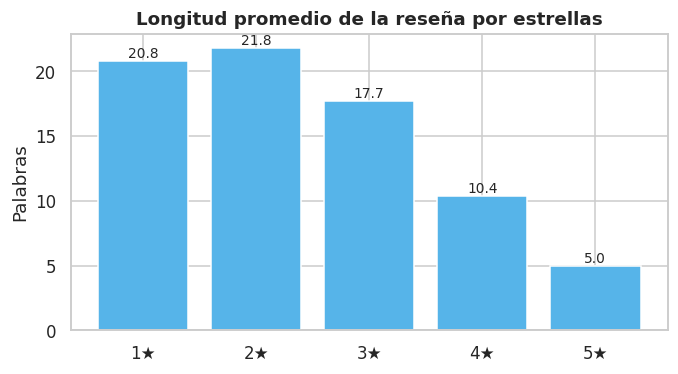

,mean,median
calificacion,,
1,20.8,14.0
2,21.8,16.0
3,17.7,12.0
4,10.4,5.0
5,5.0,2.0


In [ ]:
longitud = df.groupby("calificacion")["n_palabras"].agg(["mean", "median"]).round(1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(longitud.index.astype(str) + "★", longitud["mean"], color=COLOR_BASE)
for i, v in enumerate(longitud["mean"]):
    ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Longitud promedio de la reseña por estrellas")
ax.set_ylabel("Palabras")
guardar_figura(fig, "longitud_por_estrellas", modulo=3)
plt.show()

longitud

## 3.2 — Evolución en el tiempo
Reseñas por mes y porcentaje de negativas. Noviembre de 2025 y noviembre de 2026 son meses incompletos (la ventana va del 04/11/2025 al 03/11/2026).

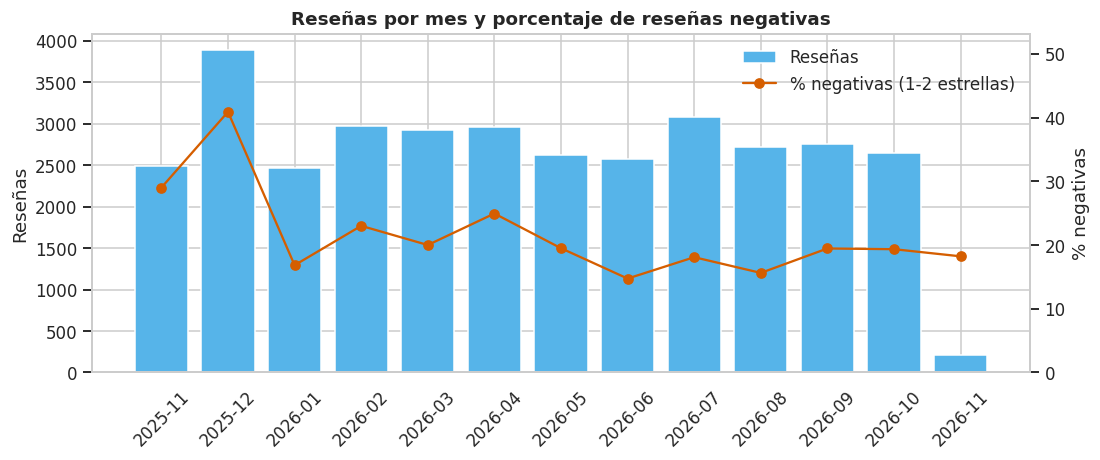

,reseñas,pct_negativas
fecha,,
2025-12-06,767,81.4
2025-12-15,397,77.1
2026-02-03,262,47.7
2025-11-20,215,58.1
2026-04-23,198,26.3


In [ ]:
df["mes"] = df["fecha"].dt.to_period("M").astype(str)

def pct_negativas(grupo):
    """Porcentaje de reseñas negativas (1-2 estrellas) dentro de un grupo"""
    return (grupo == "Negativo").mean()*100

mensual = df.groupby("mes").agg(reseñas=("id_comentario", "size"),
                                pct_negativas = ("grupo_estrellas", pct_negativas))

# Barras = volumen de reseñas; línea = % negativas (eje derecho)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(mensual.index, mensual["reseñas"], color=COLOR_BASE, label="Reseñas")
ax.set_ylabel("Reseñas")
ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx()
ax2.plot(mensual.index, mensual["pct_negativas"], color=COLORES_SENTIMIENTO["Negativo"],
         marker="o", label="% negativas (1-2 estrellas)")
ax2.set_ylabel("% negativas")
ax2.set_ylim(0, mensual["pct_negativas"].max() * 1.3)
ax2.grid(False)
ax.set_title("Reseñas por mes y porcentaje de reseñas negativas")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88), frameon=False)
guardar_figura(fig, "evolucion_mensual", modulo=3)
plt.show()

# Los 5 días con más reseñas: ¿coinciden con caídas?
dias_pico = (df.groupby(df["fecha"].dt.date)
               .agg(reseñas=("id_comentario", "size"), pct_negativas=("grupo_estrellas", pct_negativas))
               .nlargest(5, "reseñas").round(1))
dias_pico

## 3.3 - Palabras más frecuentes

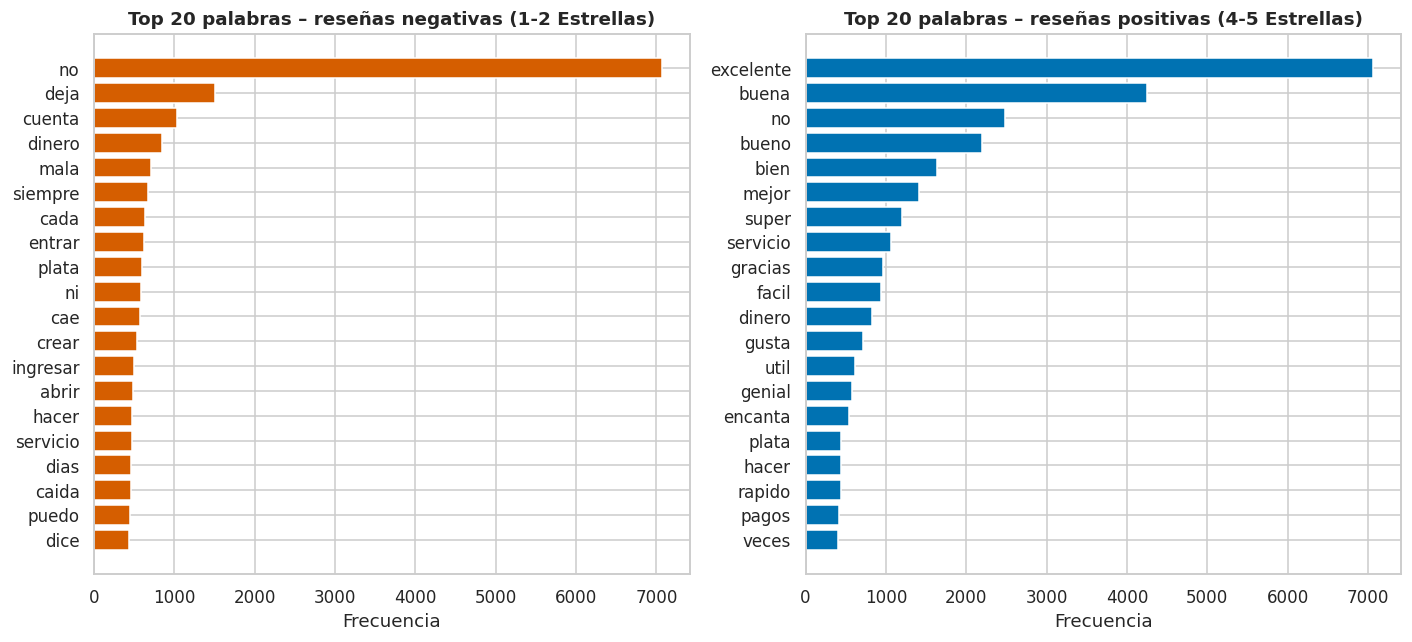

In [ ]:
def top_palabras(textos, n = 20):
  """Las n palabras más frecuentes de una serie de textos tokenizados"""
  return pd.Series(Counter(" ".join(textos).split())).nlargest(n)

# Comparación lado a lado: negativas vs positivas
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, grupo in zip(axes, ["Negativo", "Positivo"]):
    top = top_palabras(df.loc[df["grupo_estrellas"] == grupo, "tokens"]).sort_values()
    ax.barh(top.index, top.values, color=COLORES_SENTIMIENTO[grupo])
    ax.set_title(f"Top 20 palabras – reseñas {ETIQUETAS[grupo]}")
    ax.set_xlabel("Frecuencia")
fig.tight_layout()
guardar_figura(fig, "top_palabras", modulo=3)
plt.show()

## 3.4 — Bigramas
Un bigrama es un par de palabras seguidas ("no deja"). Da más contexto que una palabra suelta y permite una primera identificación de temas recurrentes.

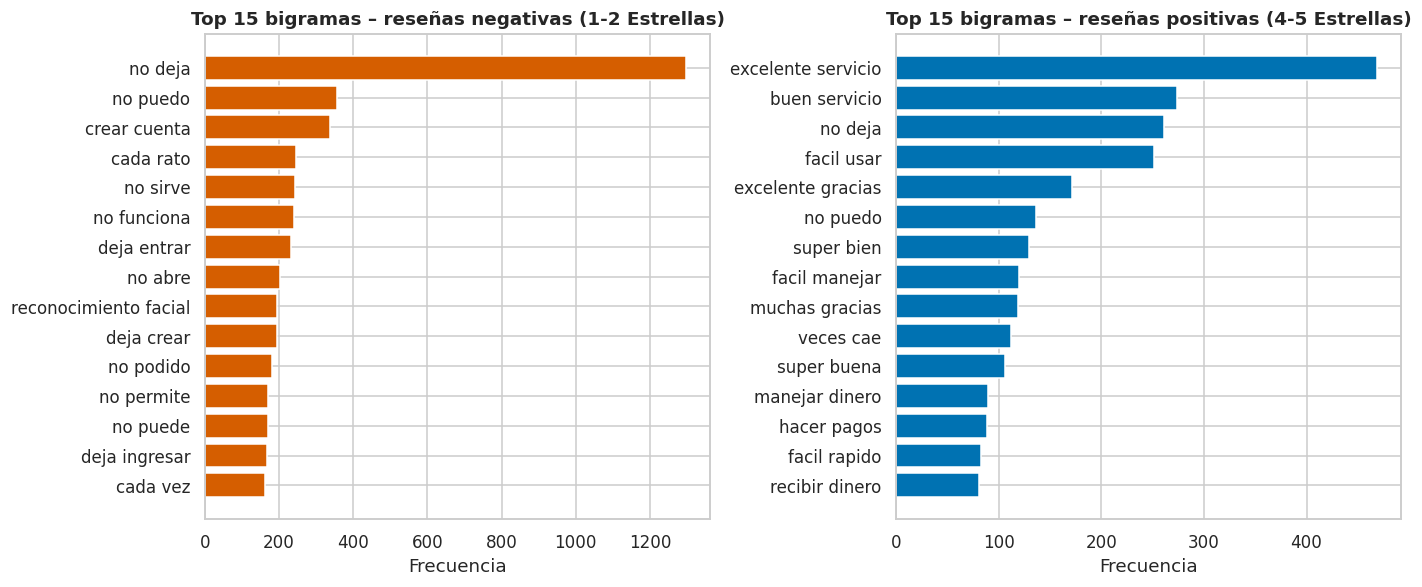

In [ ]:
def top_bigramas(textos, n = 15):
    """Los n pares de palabras consecutivas más frecuentes"""
    conteo = Counter()
    for texto in textos:
      palabras = texto.split()
      conteo.update(" ".join(par) for par in zip(palabras, palabras[1:]))
    return pd.Series(conteo).nlargest(n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, grupo in zip(axes, ["Negativo", "Positivo"]):
    top = top_bigramas(df.loc[df["grupo_estrellas"] == grupo, "tokens"]).sort_values()
    ax.barh(top.index, top.values, color=COLORES_SENTIMIENTO[grupo])
    ax.set_title(f"Top 15 bigramas – reseñas {ETIQUETAS[grupo]}")
    ax.set_xlabel("Frecuencia")
fig.tight_layout()
guardar_figura(fig, "top_bigramas", modulo=3)
plt.show()

## 3.5 — Nubes de palabras
Un solo color por grupo para que todas las palabras se lean. `collocations=False` evita que la nube repita bigramas ya mostrados en 3.4.

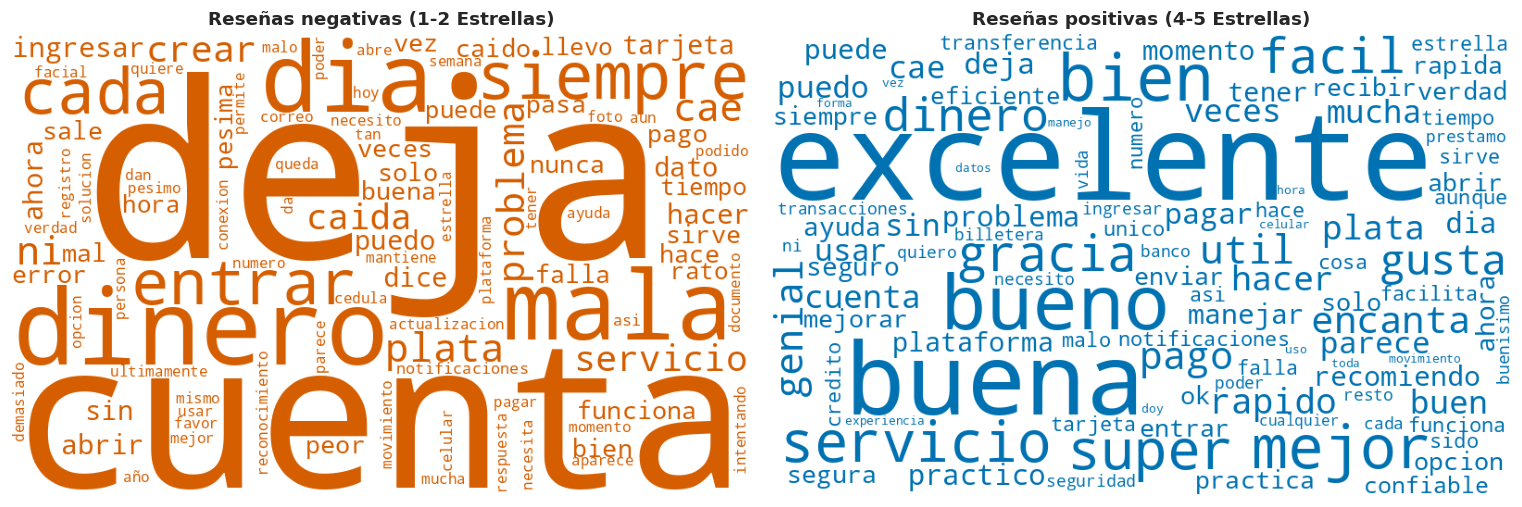

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, grupo in zip(axes, ["Negativo", "Positivo"]):
    texto = " ".join(df.loc[df["grupo_estrellas"] == grupo, "tokens"])
    nube = WordCloud(width=800, height=500, background_color="white", max_words=100,
                     color_func=lambda *args, c=COLORES_SENTIMIENTO[grupo], **kwargs: c,
                     collocations=False, random_state=SEMILLA).generate(texto)
    ax.imshow(nube)
    ax.axis("off")
    ax.set_title(f"Reseñas {ETIQUETAS[grupo]}")
fig.tight_layout()
guardar_figura(fig, "nubes_palabras", modulo=3)
plt.show()

## 3.6 - Emojis
Frecuencia de cada emoji (contado una vez por reseña) y estrellas promedio de las reseñas donde aparece. Se muestra en tabla porque Matplotlib no dibuja emojis.

In [ ]:
# Una fila por emoji distinto en cada reseña (set evita contar repeticiones)
emojis_resena = (df.assign(emoji=df["emojis"].str.split().apply(set)).explode("emoji").dropna(subset=["emoji"]))

tabla_emojis = (emojis_resena.groupby("emoji").agg(reseñas=("id_comentario", "size"), estrellas_promedio=("calificacion", "mean")).nlargest(15, "reseñas").round(2))

print(f"Reseñas con emojis: {(df['n_emojis'] > 0).sum():,} | emojis distintos: {emojis_resena['emoji'].nunique()}")
tabla_emojis

Reseñas con emojis: 2,655 | emojis distintos: 301


,reseñas,estrellas_promedio
emoji,,
👍,535,4.80
👌,422,4.84
😡,94,1.33
😔,91,2.51
🙏,85,4.54
😊,71,4.77
☺,70,4.64
❤,64,4.91
💯,63,4.73


## 3.7 — Reseñas extremas
- **Más votadas** por otros usuarios (`me_gusta`): opiniones que la comunidad respalda.
- **Día pico:** ejemplos de reseñas negativas del día con más reseñas del año.

In [ ]:
pd.set_option("display.max_colwidth", 200) # Mostrar el texto completo
COLUMNAS = ["texto", "calificacion", "me_gusta", "fecha"]

# Las 3 más votadas de cada grupo
for grupo in ["Negativo", "Positivo"]:
    print(f"\n--- Más votadas: reseñas {ETIQUETAS[grupo]} ---")
    display(df[df["grupo_estrellas"] == grupo].nlargest(3, "me_gusta")[COLUMNAS])

# Día con más reseñas: 5 ejemplos negativos con contenido (4+ palabras)
dia_pico = dias_pico.index[0]
pico = df[(df["fecha"].dt.date == dia_pico) & (df["grupo_estrellas"] == "Negativo") & (df["flag_corta"] == 0)]
print(f"\n--- Día pico: {dia_pico} ---")
pico.sample(5, random_state=SEMILLA)[COLUMNAS]


--- Más votadas: reseñas negativas (1-2 Estrellas) ---


,texto,calificacion,me_gusta,fecha
3559,"está muy fuerte el tema del 4x1000 en todos los bancos siempre me quejaré de que el banquero tenga un subsidio y luego salga a querer quitarle a de los demás, menos mal no cobra nequi por uso, si ...",2,1254,2026-09-22 14:33:45
30279,"Cuando uno trata de entrar, así marque bien sus datos aparece: !Ups, algo salió mal! Luego sí deja entrar. Ha fallado mucho desde los últimos meses.",2,737,2025-12-09 00:55:03
32139,yo creo que pagaron por Reviews porque nadie le daría 5 estrellas a una app que se la pasa caída la mayor parte del dia.,1,540,2025-11-27 21:57:21



--- Más votadas: reseñas positivas (4-5 Estrellas) ---


,texto,calificacion,me_gusta,fecha
27937,"Nequi me ha sido muy útil a la hora de realizar pagos por PSE y transferir montos a conocidos. En momentos de mucho tráfico en la red, puede que se demore un poco, pero el servicio es bueno y el h...",5,931,2026-01-01 00:02:36
31784,"Bueno...ha sido muy útil el uso de la App, ya que se puede decir que, hasta la fecha, es la más usada por los usuarios y me ha permitido realizar transacciones exitosas y confiables 🙏. Aunque, alg...",4,386,2025-12-01 17:11:37
24607,"Nequi es una aplicación muy fácil de manejar plata sin necesidad de banco. Bastante rápida para enviar y recibir dinero y sirve para pagar servicios o recargar. Lo malo es que a veces se cae, se p...",5,364,2026-02-08 13:49:25



--- Día pico: 2025-12-06 ---


,texto,calificacion,me_gusta,fecha
30727,"Es una aplicación muy buena, pero se cae últimamente DEMASIADO, entonces uno con el dinero ahí, no aguanta, miren bien que es lo que van hacer.",1,0,2025-12-06 21:17:25
30597,muy mala aplicación últimamente,1,0,2025-12-06 22:47:03
30988,solo vive caído se la pasan todos los días trabajando para mejorar 🤦🏻‍♂️🤦🏻‍♂️🤦🏻‍♂️🤦🏻‍♂️,1,0,2025-12-06 18:23:53
30614,"que asco, todo el día 06-12-2025 sin funcionar, eso les pasa por hacer un pacto con el diablo, si estuvieran con Dios , no hubieran hechado a perder la aplicación",1,0,2025-12-06 22:39:28
30996,"Pésima, me dejo varada toda la mañana y es la hora y nada.",1,0,2025-12-06 18:18:11


## 3.8 — **Hallazgos – EDA**
- **Volumen y longitud:** 34.328 reseñas, con una mediana de 4 palabras. Los insatisfechos escriben unas **4 veces más** que los de 5 estrellas (20,8 palabras en 1 estrella frente a 5,0 en 5 estrellas): quien se queja explica su problema; quien está satisfecho solo califica.
- **Crisis de diciembre de 2025:** el mes con más reseñas (3.892) y con 40,9 % de negativas, frente a ~20 % el resto del año. El 06/12/2025 llegaron 767 reseñas, el 81,4 % negativas; el 15/12/2025 (día de quincena), 397, con 77,1 % negativas. Ambas fechas coinciden con caídas reportadas por la prensa.
- **Temas preliminares (bigramas en 1-2 estrellas):** acceso a la cuenta ("no deja", "deja entrar", "deja ingresar", "no abre"), registro y validación de identidad ("crear cuenta", "reconocimiento facial") y estabilidad ("cada rato", "no funciona", "no sirve").
- **Lo que se valora (4-5 estrellas):** el servicio ("excelente servicio", "buen servicio") y la facilidad de uso ("facil usar", "facil manejar").
- **Reseñas mixtas:** "no deja", "no puedo" y "veces cae" aparecen también en reseñas de 4-5 estrellas. Hay usuarios satisfechos que, aun así, reportan fallas. Las estrellas no cuentan toda la historia.
- **Emojis:** el 7,7 % de las reseñas tiene emojis (301 distintos). La cara enojada y el pulgar abajo se asocian a ~1,4 estrellas, mientras que la cara enamorada y el corazón se asocian a ~4,9 estrellas. Los emojis sí cargan sentimiento, lo que justifica la capa de emojis del módulo 5.

# 4 - Clustering de comentarios (K-Means)

**Objetivo:** descubrir de qué hablan los usuarios **sin reglas previas**. Los grupos encontrados sirven para construir y contrastar el diccionario de temas (módulo 7).

**Método:**
1. Cada reseña se convierte en un **embedding**: un vector de 384 números que representa su significado. Reseñas con significado parecido quedan cerca, aunque usen palabras distintas ("se cae" ≈ "no carga").
2. **K-Means** agrupa los vectores cercanos.
3. Cada grupo se nombra con sus palabras más distintivas (TF-IDF).

**Modelo:** `paraphrase-multilingual-MiniLM-L12-v2`, entrenado en más de 50 idiomas (incluido el español), liviano y rápido.

## 4.2 - Selección de reseñas
Solo entran reseñas con 4 palabras o más (`flag_corta == 0`). Las reseñas muy cortas ("excelente", "buena") formarían grupos por longitud, no por tema.

In [ ]:
# Reseñas con contenido suficiente para identificar un tema
mascara_cluster = df["flag_corta"] == 0
df_cl = df[mascara_cluster].copy()

print(f"Reseñas para clustering: {len(df_cl):,} ({mascara_cluster.mean():.1%} del total)")
df_cl["grupo_estrellas"].value_counts(normalize=True).reindex(GRUPOS).mul(100).round(1)

Reseñas para clustering: 17,349 (50.5% del total)


,proportion
grupo_estrellas,
Negativo,39.1
Neutral,7.2
Positivo,53.7


## 4.3 — Embeddings
Se usa `texto_modelo` (limpieza mínima): el modelo entiende tildes, signos y contexto.

Los vectores se **normalizan** (largo 1). Así, la distancia que usa K-Means equivale a la similitud de coseno, la medida estándar para comparar significados. **No se aplica `StandardScaler`**: deformaría el espacio semántico del modelo.

Los embeddings se guardan en caché (`.npy`, formato de NumPy para matrices) para no recalcularlos en cada corrida.

In [ ]:
NOMBRE_MODELO = "paraphrase-multilingual-MiniLM-L12-v2"
CACHE_EMBEDDINGS = DIR_MODELOS / "04_embeddings.npy"
textos = df_cl["texto_modelo"].tolist()

# Usar la caché solo si corresponde a las mismas reseñas (mismo número de filas)
if CACHE_EMBEDDINGS.exists() and np.load(CACHE_EMBEDDINGS).shape[0] == len(textos):
    X = np.load(CACHE_EMBEDDINGS)
    print("Embeddings cargados desde caché")
else:
    modelo_emb = SentenceTransformer(NOMBRE_MODELO, device=DISPOSITIVO)
    X = modelo_emb.encode(textos, batch_size=128, show_progress_bar=True, normalize_embeddings=True)
    np.save(CACHE_EMBEDDINGS, X)

print("Matriz de embeddings:", X.shape)

Embeddings cargados desde caché
Matriz de embeddings: (17349, 384)


## 4.4 — Elección de K
Se prueban de 3 a 10 grupos con tres criterios:
- **Codo (inercia):** dónde deja de mejorar mucho al agregar grupos.
- **Silhouette:** qué tan separados están los grupos (−1 a 1). Con texto suele ser bajo (0,02–0,10): los temas se mezclan en la conversación real.
- **Tamaño mínimo:** ningún grupo debería tener menos del 3 % de las reseñas.

La decisión final también considera el **sentido de negocio**: grupos interpretables y distintos entre sí.

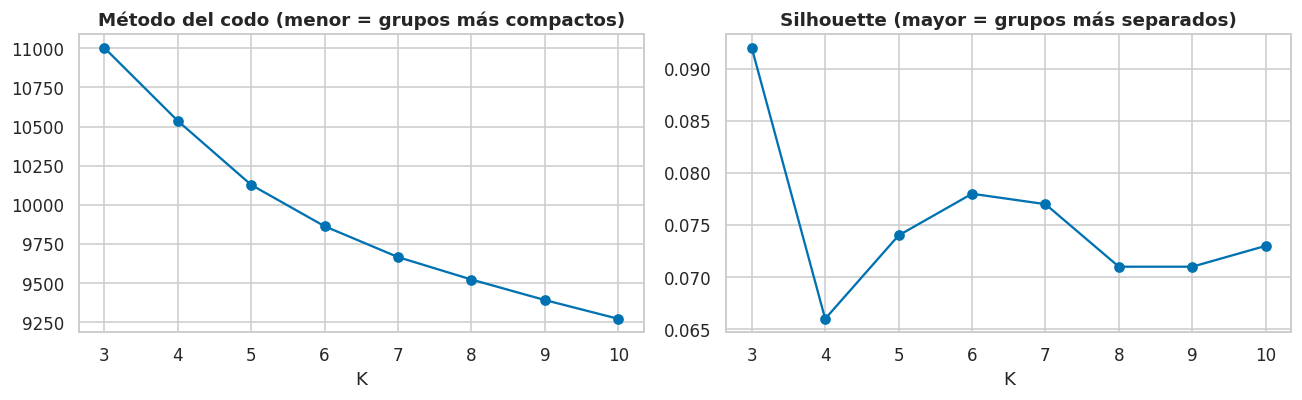

,inercia,silhouette,cluster_min_pct
k,,,
3,11002.748,0.092,31.039
4,10536.414,0.066,15.488
5,10127.585,0.074,15.010
6,9863.459,0.078,10.957
7,9666.452,0.077,10.565
8,9523.111,0.071,9.424
9,9392.209,0.071,7.666
10,9272.291,0.073,5.943


In [ ]:
filas = []

for k in range (3,11):
  km = KMeans(n_clusters = k, n_init = 10, random_state = SEMILLA).fit(X)
  filas.append({
      "k" : k,
      "inercia" : km.inertia_, # Muestra de 5.000 para acelerar el cálculo (Silhouette compara todos los pares
      "silhouette" : silhouette_score(X, km.labels_, sample_size = 5000, random_state = SEMILLA),
      "cluster_min_pct": np.bincount(km.labels_).min() / len(X) * 100,
      })

puntajes_k = pd.DataFrame(filas).set_index("k").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(puntajes_k.index, puntajes_k["inercia"], marker="o", color=COLORES_CLUSTER[0])
axes[0].set_title("Método del codo (menor = grupos más compactos)")
axes[1].plot(puntajes_k.index, puntajes_k["silhouette"], marker="o", color=COLORES_CLUSTER[0])
axes[1].set_title("Silhouette (mayor = grupos más separados)")
for ax in axes:
    ax.set_xlabel("K")
fig.tight_layout()
guardar_figura(fig, "eleccion_k", modulo=4)
plt.show()

puntajes_k

## 4.5 — Modelo final
K se fija según los criterios de 4.4 (ver justificación en los hallazgos).

In [ ]:
K_FINAL = 6   # Valor provisional: se ajusta después de revisar índice 4.3

kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEMILLA).fit(X)
df_cl["cluster"] = kmeans.labels_
df_cl["cluster"].value_counts().sort_index()

,count
cluster,
0,2750
1,2344
2,3441
3,3105
4,3808
5,1901


## 4.6 — ¿De qué habla cada grupo?
K-Means solo numera los grupos. Esta celda los traduce a palabras:
1. **Términos clave:** las palabras que más distinguen a cada grupo frente al resto (TF-IDF). *TF-IDF da un puntaje alto a una palabra si cumple dos condiciones: Se repite mucho dentro del grupo. Y: Es poco común en el resto de reseñas.*
2. **Nombre:** los 3 primeros términos clave (más claro que "Grupo 0" y no cambia entre corridas).
3. **Reseñas típicas:** las 3 más cercanas al centro de cada grupo, para confirmar el tema con ejemplos reales.

La palabra "no" se ignora solo aquí: aparece en casi todas las quejas y haría que todos los grupos negativos se llamaran igual.

In [ ]:
# TF-IDF sobre tokens (sin negaciones solo para nombrar)
tfidf = TfidfVectorizer(min_df=5, stop_words=["no", "ni", "sin", "nunca"])
M = tfidf.fit_transform(df_cl["tokens"])
terminos = np.array(tfidf.get_feature_names_out())

def top_terminos(c, n=8):
    """Los n términos con mayor TF-IDF promedio en el cluster c."""
    media = np.asarray(M[(df_cl["cluster"] == c).values].mean(axis=0)).ravel()
    return terminos[media.argsort()[::-1][:n]].tolist()

TERMINOS_CLUSTER = {c: top_terminos(c) for c in range(K_FINAL)}
NOMBRES_CLUSTER = {c: " · ".join(t[:3]) for c, t in TERMINOS_CLUSTER.items()}
assert len(set(NOMBRES_CLUSTER.values())) == K_FINAL, "Hay nombres de cluster repetidos"
df_cl["cluster_nombre"] = df_cl["cluster"].map(NOMBRES_CLUSTER)

# Perfil: tamaño, estrellas y % de reseñas negativas por cluster
perfil_cluster = (df_cl.groupby("cluster_nombre")
                    .agg(reseñas=("id_comentario", "size"),
                         estrellas_promedio=("calificacion", "mean"),
                         pct_negativas=("grupo_estrellas", pct_negativas))
                    .assign(pct_total=lambda d: d["reseñas"] / d["reseñas"].sum() * 100)
                    .sort_values("reseñas", ascending=False).round(1))
perfil_cluster["terminos_clave"] = perfil_cluster.index.map(
    {NOMBRES_CLUSTER[c]: ", ".join(t) for c, t in TERMINOS_CLUSTER.items()})
display(perfil_cluster)

# Reseñas más cercanas al centro de cada cluster (las más "típicas")
df_cl["distancia_centro"] = kmeans.transform(X).min(axis=1)
for nombre in perfil_cluster.index:
    print(f"\n--- {nombre} ---")
    for texto in df_cl[df_cl["cluster_nombre"] == nombre].nsmallest(3, "distancia_centro")["texto"]:
        print("•", texto[:150])

,reseñas,estrellas_promedio,pct_negativas,pct_total,terminos_clave
cluster_nombre,,,,,
deja · cuenta · crear,3808,2.2,66.3,21.9,"deja, cuenta, crear, entrar, puedo, notificaciones, abrir, ingresar"
excelente · mejor · buena,3441,4.7,4.6,19.8,"excelente, mejor, buena, bueno, servicio, gracias, gusta, bien"
deja · abrir · entrar,3105,2.0,69.2,17.9,"deja, abrir, entrar, mala, cada, abre, ingresar, cae"
cae · cada · veces,2750,2.3,62.2,15.9,"cae, cada, veces, siempre, caida, caido, mala, plata"
buena · excelente · facil,2344,4.8,2.1,13.5,"buena, excelente, facil, usar, mejor, util, encanta, gusta"
dinero · pagos · excelente,1901,4.4,10.3,11.0,"dinero, pagos, excelente, pagar, buena, mejor, facil, hacer"



--- deja · cuenta · crear ---
• porque no me dejan entrar a mi cuenta de Nequi
• no me llegan notificación del dinero que entra. y ya entré a notificaciónes y no se arregla
• muy malo el nequi no me quiere dejar abrir la cuenta

--- excelente · mejor · buena ---
• muy buena sirve mucho
• muy buena la nequiii
• muy buena la apricacion

--- deja · abrir · entrar ---
• que pasa con su app últimamente no sirven se la pasa fallando todo el tiempo apenas pueda retiro mi plata de su aplicación no valla a ser que se me te
• falla mucho la aplicación y me deja botado cuando la voy a utilizar
• que mal servicio de esta App. mantiene caída la plataforma

--- cae · cada · veces ---
• q mal que acada rato está caído, ya no es confiable
• lo malo es que mantiene muy caido
• muy malo ese nequi no sirve de nada aparte de q se cae a cada rato y se demora

--- buena · excelente · facil ---
• una muy buena aplicación
• Es de maciado buena la aplicación
• muy buena la aplicación. .

--- dinero · pagos · 

## 4.7 - Visualización

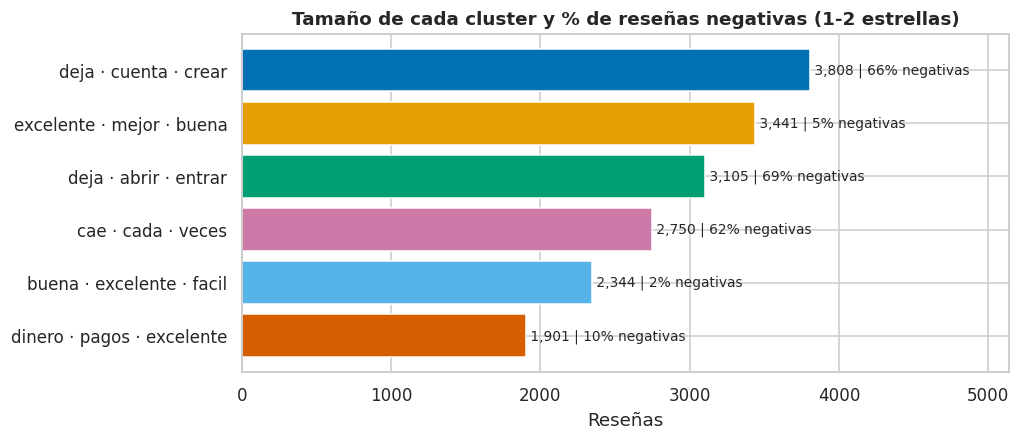

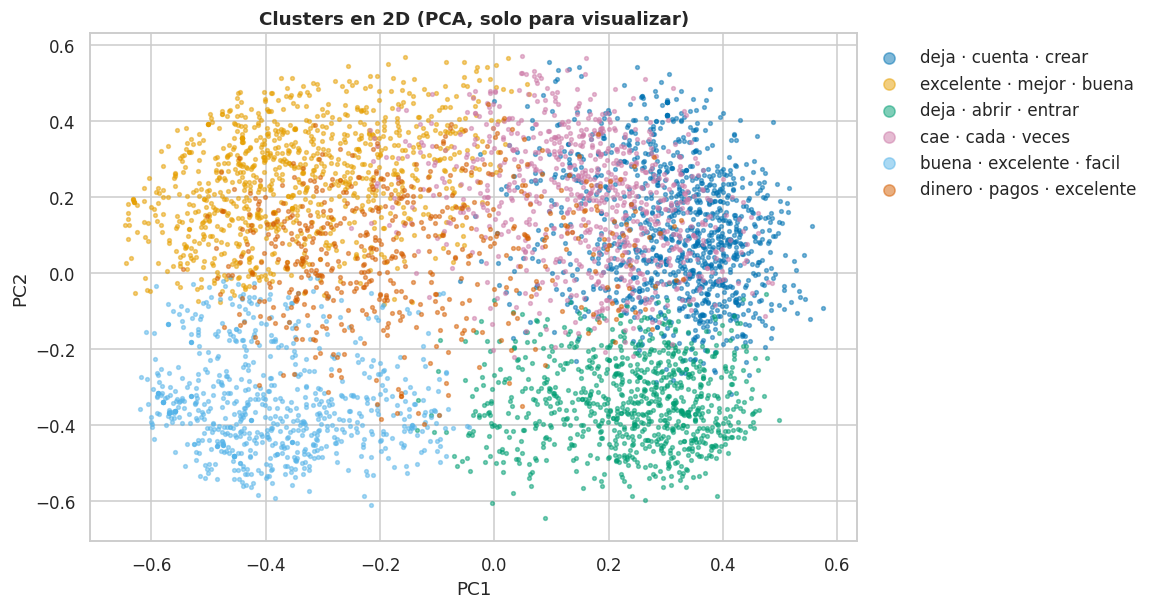

In [ ]:
# Colores fijos por cluster, en el orden del perfil (de mayor a menor tamaño)
ORDEN_CLUSTER = perfil_cluster.index.tolist()
COLOR_POR_CLUSTER = dict(zip(ORDEN_CLUSTER, COLORES_CLUSTER))

# Tamaño de cada cluster y su % de reseñas negativas
fig, ax = plt.subplots(figsize=(9, 4))
datos = perfil_cluster.iloc[::-1]   # el más grande arriba
ax.barh(datos.index, datos["reseñas"], color=[COLOR_POR_CLUSTER[n] for n in datos.index])
for i, (n, neg) in enumerate(zip(datos["reseñas"], datos["pct_negativas"])):
    ax.text(n, i, f" {n:,} | {neg:.0f}% negativas", va="center", fontsize=9)
ax.set_title("Tamaño de cada cluster y % de reseñas negativas (1-2 estrellas)")
ax.set_xlabel("Reseñas")
ax.set_xlim(0, datos["reseñas"].max() * 1.35)
guardar_figura(fig, "tamano_clusters", modulo=4)
plt.show()

# Proyección 2D con PCA (solo para visualizar; muestra de 5.000 para que se lea)
idx = np.random.default_rng(SEMILLA).choice(len(X), 5000, replace=False)
coords = PCA(n_components=2, random_state=SEMILLA).fit_transform(X[idx])
etiquetas = df_cl["cluster_nombre"].values[idx]

fig, ax = plt.subplots(figsize=(9, 6))
for nombre in ORDEN_CLUSTER:
    m = etiquetas == nombre
    ax.scatter(coords[m, 0], coords[m, 1], s=6, alpha=0.5, color=COLOR_POR_CLUSTER[nombre], label=nombre)
ax.set_title("Clusters en 2D (PCA, solo para visualizar)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=3, frameon=False, bbox_to_anchor=(1, 1))
guardar_figura(fig, "clusters_pca", modulo=4)
plt.show()

## 4.8  — Asignación, exportación y modelo
Las reseñas cortas quedan como "Sin cluster (corta)". El modelo se guarda con todo lo necesario para asignar nuevas reseñas.

In [ ]:
# Asignar el cluster a la base completa (alineado por índice; re-ejecutable)
df["cluster_nombre"] = df_cl["cluster_nombre"]
df["cluster_nombre"] = df["cluster_nombre"].fillna("Sin cluster (corta)")

# Exportar el perfil
perfil_cluster.to_excel(DIR_SALIDAS / "04_perfil_clusters.xlsx")

# Guardar el modelo y verificar que reproduce las etiquetas
joblib.dump({"modelo_embeddings": NOMBRE_MODELO, "kmeans": kmeans,
             "nombres_cluster": NOMBRES_CLUSTER, "min_palabras": 4},
            DIR_MODELOS / "04_kmeans_comentarios.joblib")
guardado = joblib.load(DIR_MODELOS / "04_kmeans_comentarios.joblib")

print("El modelo recargado reproduce las etiquetas:", (guardado["kmeans"].predict(X) == df_cl["cluster"].values).all())

df["cluster_nombre"].value_counts()

El modelo recargado reproduce las etiquetas: True


,count
cluster_nombre,
Sin cluster (corta),16979
deja · cuenta · crear,3808
excelente · mejor · buena,3441
deja · abrir · entrar,3105
cae · cada · veces,2750
buena · excelente · facil,2344
dinero · pagos · excelente,1901


## 4.9 — **Hallazgos – Clustering**
- **Reseñas agrupadas:** 17.349 (50,5 % de la base). Las reseñas cortas quedan fuera porque formarían grupos por longitud, no por tema.
- **K = 6:** K = 3 tiene el silhouette más alto (0,092), pero solo separaría grandes bloques. K = 6 es el siguiente pico (0,078), su grupo más pequeño tiene el 11,0 % de las reseñas y distingue problemas que requieren acciones distintas. El silhouette es bajo, como se espera en texto: los grupos son una **partición útil**, no grupos naturales separados.
- **Tres grupos de problemas (55,7 % de las reseñas agrupadas):**
  - *Acceso, registro y notificaciones* ("deja · cuenta · crear"): 3.808 reseñas, 66,3 % negativas.
  - *La app no abre o falla al usarla* ("deja · abrir · entrar"): 3.105 reseñas, 69,2 % negativas. Es el grupo más negativo.
  - *Caídas frecuentes* ("cae · cada · veces"): 2.750 reseñas, 62,2 % negativas.
- **Tres grupos de valoración:** elogio general (3.441; 4,6 % negativas), facilidad de uso (2.344; 2,1 %) y pagos y manejo del dinero (1.901; 10,3 %).
- **Lectura de negocio:** cuando los usuarios escriben con detalle, más de la mitad describe un problema de **acceso o estabilidad**. Lo que más se valora es la **facilidad** y la **utilidad para pagar**.
- **Limitación:** los nombres automáticos repiten palabras ("excelente" aparece en tres grupos) y los dos grupos de acceso se superponen en parte (ambos contienen "deja"). Por eso los temas se precisan con un diccionario en el módulo 7.
- **Uso en el proyecto:** los términos clave de cada grupo alimentan el diccionario de temas del módulo 7.

# 5 — Análisis de sentimientos (NLP)
Cada reseña se clasifica como **Positiva, Neutral o Negativa** en dos capas:
1. **Modelo de lenguaje** (`pysentimiento`): lee el texto completo y entiende contexto y negaciones.
2. **Capa de emojis:** un diccionario con pesos que rescata las reseñas que son solo emojis y desempata las neutrales.

Después se agregan **etiquetas adicionales**: pregunta, mixta, intención de abandono, riesgo reputacional, recomendación y afinidad de marca.

### Modelo de sentimiento
**Modelo:** `pysentimiento` con RoBERTuito, un modelo entrenado con millones de tuits en español y ajustado para clasificar sentimiento (Pérez et al., 2021). Se eligió porque:
- **Entiende español directamente**: no requiere traducir (TextBlob solo funciona en inglés).
- **Fue entrenado con texto informal** (redes sociales), similar a las reseñas: errores, jerga, emojis.
- Entrega la **probabilidad** de cada clase, no solo la etiqueta.

**Puntaje del modelo:** `p_pos − p_neg`, de −1 (muy negativo) a +1 (muy positivo).

Para ahorrar tiempo, se clasifican solo los **textos únicos** y el resultado se guarda en caché (`.xlsx`).

In [ ]:
CACHE_SENTIMIENTO = DIR_SALIDAS / "05_cache_sentimiento.xlsx"
ETIQUETAS_MODELO = {"POS" : "Positivo", "NEU" : "Neutral", "NEG" : "Negativo"}

if CACHE_SENTIMIENTO.exists():
  # dtype = str exita que textos como "10" se lean como números y no se puedan cruzar
  cache = pd.read_excel(CACHE_SENTIMIENTO, dtype = {"texto_modelo" : str})
  print("Resultados cargados desde caché")
else:
  textos_unicos = df["texto_modelo"].drop_duplicates().tolist()
  print(f"Textos únicos a clasificar: {len(textos_unicos):,}")
  analizador = create_analyzer(task = "sentiment", lang = "es") # Usa la GPU si está disponible
  salidas = analizador.predict(textos_unicos)
  cache = pd.DataFrame({
      "texto_modelo" : textos_unicos,
      "etiqueta" : [s.output for s in salidas],
      "p_pos": [s.probas["POS"] for s in salidas],
        "p_neu": [s.probas["NEU"] for s in salidas],
        "p_neg": [s.probas["NEG"] for s in salidas],
    })

cache.to_excel(CACHE_SENTIMIENTO, index=False)

# Llevar los resultados a cada reseña con map() (re-ejecutable, no duplica columnas)
resultados = cache.set_index("texto_modelo")
df["sentimiento_modelo"] = df["texto_modelo"].map(resultados["etiqueta"]).map(ETIQUETAS_MODELO)

for col in["p_pos", "p_neu", "p_neg"]:
  df[col] = df["texto_modelo"].map(resultados[col])
df["puntaje_modelo"] = df["p_pos"] - df["p_neg"]

print("Reseñas sin resultado:", df["sentimiento_modelo"].isna().sum())
df["sentimiento_modelo"].value_counts().reindex(ORDEN_SENTIMIENTO)

Resultados cargados desde caché
Reseñas sin resultado: 0


,count
sentimiento_modelo,
Negativo,9801
Neutral,11668
Positivo,12859


## 5.2 — Diccionario de emojis
- **Escala entera de −3 a +3**, inspirada en léxicos validados como AFINN (−5 a +5) y VADER (−4 a +4), simplificada a 3 intensidades por lado para que cada peso sea explicable.
- **Criterio por nivel:**

| Peso | Criterio |
|---|---|
| +3 | Amor o euforia (caras enamoradas, corazones) |
| +2 | Alegría o celebración (risa, aplausos, "100") |
| +1 | Aprobación o cortesía (pulgar arriba, sonrisa leve) |
| 0 | Ambiguo: puede ser elogio, ironía o súplica (manos juntas, cara de dinero, risa a carcajadas) |
| −1 | Tristeza leve o decepción |
| −2 | Enojo o rechazo (cara enojada, pulgar abajo, llanto) |
| −3 | Furia o asco |

- **No se usan puntajes externos directamente:** el Emoji Sentiment Ranking (Kralj Novak et al., 2015) se basa en tuits de 2015, tiene sesgo positivo y no incluye emojis recientes.
- **Selección:** los 50 emojis más frecuentes de la base (celda 3.6). El resto recibe peso 0.
- **Sin inflar repeticiones:** cada emoji distinto cuenta una vez por reseña. La suma se acota a [−3, 3] y se divide entre 3, para quedar en [−1, 1], el mismo rango del puntaje del modelo.
- **Las estrellas solo verifican:** se revisa que el promedio de estrellas crezca con el peso, **sin ajustar pesos** para mejorar esa relación.

In [ ]:
# Los 50 emojis más frecuentes, agrupados por peso según el criterio anterior
NIVELES_EMOJI = {
     3: "😍 🥰 🤩 ❤️ 😘 💜 🫶 💖 ♥️",
     2: "😃 😁 💯 👏 ⭐ 😀 ✨ 🔥 😆 🫰",
     1: "👍 👌 😊 ☺️ 🙂 😉 🤗 🫂 💪",
     0: "🙏 🤑 💰 😎 🤣 🥲 🥹 ❤️‍🩹",
    -1: "😔 😞 😒 🙄 😕 🤦 😢",
    -2: "😡 👎 😭 😤 😠",
    -3: "🤬 💩",
}
# Se normalizan las llaves igual que en 2.3 (sin tonos ni selector de variación)
PESOS_EMOJI = {PATRON_TONOS.sub("", e): peso for peso, lista in NIVELES_EMOJI.items() for e in lista.split()}
print("Emojis en el diccionario:", len(PESOS_EMOJI))

# Cobertura sobre los emojis reales de la base (emojis_resena viene de 3.6)
cubierto = emojis_resena["emoji"].isin(PESOS_EMOJI)
pct_resenas = emojis_resena.loc[cubierto, "id_comentario"].nunique() / emojis_resena["id_comentario"].nunique()
print(f"Cobertura: {cubierto.mean():.1%} de los usos | {pct_resenas:.1%} de las reseñas con emoji")

# Verificación de signo: ¿suben las estrellas con el peso? (solo se revisa, no se ajusta)
verificacion = (emojis_resena.assign(peso=emojis_resena["emoji"].map(PESOS_EMOJI))
                  .groupby("peso")["calificacion"].agg(usos="size", estrellas_promedio="mean").round(2))
verificacion

Emojis en el diccionario: 50
Cobertura: 77.7% de los usos | 84.5% de las reseñas con emoji


,usos,estrellas_promedio
peso,,
-3.0,33,1.18
-2.0,222,1.48
-1.0,233,2.33
0.0,229,4.38
1.0,1222,4.79
2.0,337,4.71
3.0,306,4.81


## 5.3 — Sentimiento final
Reglas de combinación, en orden:
1. **Sin letras ni emojis** ("10/10"): Neutral.
2. **Solo emojis**, o **modelo Neutral con emojis de peso distinto de 0**: decide el signo del puntaje de emojis.
3. **En los demás casos**: decide el modelo. El texto tiene más información que un emoji.

In [ ]:
def signo(puntaje):
    """Convierte un puntaje en clase de sentimiento"""
    return "Positivo" if puntaje > 0 else "Negativo" if puntaje < 0 else "Neutral"

def puntaje_emojis(cadena):
    """Suma los pesos de los emojis distintos de la reseña, acotada a [-3 , 3] y escalada a [-1 , 1]"""
    total = sum(PESOS_EMOJI.get(e , 0) for e in set(cadena.split()))
    return np.clip(total, -3 , 3) / 3

def sentimiento_final(fila):
    """Aplica las reglas de combinación del modelo + emojis"""
    if fila["flag_sin_texto"] == 1:
      return "Neutral"
    if fila["flag_solo_emoji"] == 1 or (fila["sentimiento_modelo"] == "Neutral" and fila["puntaje_emoji"] != 0):
      return signo(fila["puntaje_emoji"])
    return fila["sentimiento_modelo"]

df["puntaje_emoji"] = df["emojis"].apply(puntaje_emojis)
df["sentimiento"] = df.apply(sentimiento_final, axis = 1)
df["ajuste_emoji"] = (df["sentimiento"] != df["sentimiento_modelo"]).astype(int)

print(f"Reseñas ajustadas por emojis: {df["ajuste_emoji"].sum():,}")
pd.crosstab(df["sentimiento_modelo"], df["sentimiento"], margins = True, margins_name = "Total")

Reseñas ajustadas por emojis: 458


sentimiento,Negativo,Neutral,Positivo,Total
sentimiento_modelo,,,,
Negativo,9800,1,0,9801
Neutral,7,11214,447,11668
Positivo,0,3,12856,12859
Total,9807,11218,13303,34328


## 5.4 — Etiquetas adicionales
Una reseña puede tener varias etiquetas (multi-etiqueta).

| Etiqueta | Regla |
|---|---|
| `es_pregunta` | Contiene "?" |
| `es_mixto` | El modelo asigna probabilidad ≥ 0,25 a positivo **y** a negativo ("buena app, pero se cae") |
| `intencion_abandono` | Anuncia que se va o se cambia ("me voy para Daviplata", "cerrar mi cuenta") |
| `riesgo_reputacional` | Menciona robo, estafa, fraude o hackeo **y** es negativa |
| `recomendacion` | Recomienda la app ("la recomiendo", "recomendada"), excluyendo "no la recomiendo" |
| `afinidad_marca` | Usa el corazón morado, color de la marca |

Las reglas buscan sobre `texto_limpio` (sin tildes ni signos), excepto la pregunta, que necesita el "?" de `texto_modelo`.

In [ ]:
UMBRAL_MIXTO = 0.25   # Probabilidad mínima de positivo y de negativo a la vez

# Patrones con límites de palabra (\b) para no confundir "rob" con "problema"
PATRONES = {
    "intencion_abandono": r"\b(?:cambiar(?:me)? de (?:app|aplicacion|banco|billetera)"
                          r"|me (?:voy|cambio|paso|pase) (?:a|para) (?:daviplata|otra|otro|bancolombia|nu)"
                          r"|(?:eliminar|cerrar|cancelar) (?:la|mi) cuenta|me voy de nequi"
                          r"|mejor daviplata|prefiero daviplata|dejar de usar|no (?:la|lo) vuelvo a usar)\b",
    "mencion_fraude": r"\b(?:rob\w*|estaf\w*|fraude\w*|hacke\w*|suplant\w*|ladron\w*"
                      r"|desaparecio|desaparecieron|demand\w*|superfinanciera)\b",
    "recomendacion": r"(?<!no )(?<!no la )(?<!no lo )\brecomiend\w*|\brecomendad\w*|\brecomendable\b",
}

df["es_pregunta"] = df["texto_modelo"].str.contains("?", regex=False).astype(int)
df["es_mixto"] = ((df["p_pos"] >= UMBRAL_MIXTO) & (df["p_neg"] >= UMBRAL_MIXTO)).astype(int)
df["intencion_abandono"] = df["texto_limpio"].str.contains(PATRONES["intencion_abandono"]).astype(int)
df["riesgo_reputacional"] = (df["texto_limpio"].str.contains(PATRONES["mencion_fraude"])
                             & (df["sentimiento"] == "Negativo")).astype(int)
df["recomendacion"] = df["texto_limpio"].str.contains(PATRONES["recomendacion"]).astype(int)
df["afinidad_marca"] = df["emojis"].str.contains("💜", regex=False).astype(int)

# Resumen: cuántas reseñas tiene cada etiqueta y qué tan negativas son
ETIQUETAS_EXTRA = ["es_pregunta", "es_mixto", "intencion_abandono", "riesgo_reputacional", "recomendacion", "afinidad_marca"]
resumen_extra = pd.DataFrame({
    "reseñas": df[ETIQUETAS_EXTRA].sum(),
    "pct_total": df[ETIQUETAS_EXTRA].mean() * 100,
    "pct_negativas": [(df.loc[df[c] == 1, "sentimiento"] == "Negativo").mean() * 100 for c in ETIQUETAS_EXTRA],
    "estrellas_promedio": [df.loc[df[c] == 1, "calificacion"].mean() for c in ETIQUETAS_EXTRA],
}).round(2)
resumen_extra

,reseñas,pct_total,pct_negativas,estrellas_promedio
es_pregunta,446,1.30,84.53,2.43
es_mixto,151,0.44,3.97,4.64
intencion_abandono,47,0.14,89.36,1.45
riesgo_reputacional,369,1.07,100.00,1.78
recomendacion,418,1.22,11.00,4.54
afinidad_marca,28,0.08,3.57,4.61


## 5.5 — Distribución del sentimiento
La tabla de la derecha compara el sentimiento del texto con las estrellas. **Es solo descriptiva:** la validación formal se hace en el módulo 6.

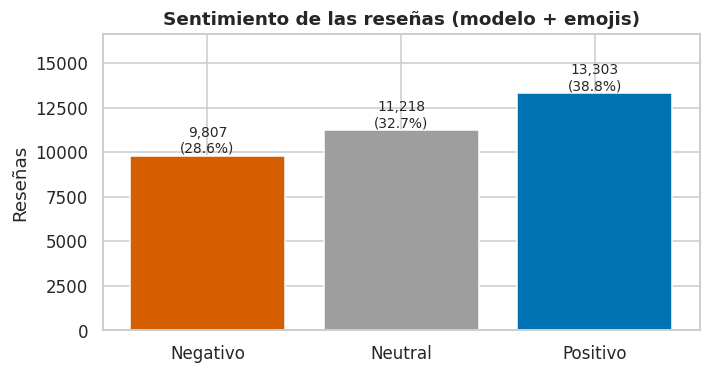

sentimiento,Negativo,Neutral,Positivo
grupo_estrellas,,,
Negativo,88.3,9.7,2.1
Neutral,65.4,24.1,10.6
Positivo,7.9,40.3,51.8


In [ ]:
dist = df["sentimiento"].value_counts().reindex(ORDEN_SENTIMIENTO, fill_value=0)
pct = dist / dist.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(dist.index, dist.values, color=[COLORES_SENTIMIENTO[s] for s in dist.index])
for i, (n, p) in enumerate(zip(dist, pct)):
    ax.text(i, n, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title("Sentimiento de las reseñas (modelo + emojis)")
ax.set_ylabel("Reseñas")
ax.set_ylim(0, dist.max() * 1.25)
guardar_figura(fig, "distribucion_sentimiento", modulo=5)
plt.show()

# Sentimiento del texto vs. grupo de estrellas (% por fila)
(pd.crosstab(df["grupo_estrellas"], df["sentimiento"], normalize="index")
   .reindex(index=ORDEN_SENTIMIENTO, columns=ORDEN_SENTIMIENTO) * 100).round(1)

## 5.6 — **Hallazgos – Sentimiento**
- **Distribución:** 38,8 % positivas, 32,7 % neutrales y 28,6 % negativas. Casi 3 de cada 10 reseñas expresan una experiencia negativa con la app.
- **Qué significa para el negocio:** el texto es más crítico que las estrellas (72,9 % de 4-5 estrellas frente a 38,8 % de texto positivo). Muchos usuarios califican bien la app en general, pero al escribir describen problemas concretos. Las estrellas sobrestiman la satisfacción; el texto muestra dónde está la fricción.
- **Capa de emojis:** ajustó 458 reseñas (1,3 %). 447 eran neutrales para el modelo y pasaron a positivas gracias a emojis claros. El efecto es pequeño porque solo el 7,7 % de las reseñas usa emojis.
- **Texto vs. estrellas:**
  - El 88,3 % de las reseñas de 1-2 estrellas tiene texto negativo: en las quejas, el modelo y el usuario coinciden.
  - El 65,4 % de las reseñas de 3 estrellas tiene texto negativo: quien da 3 estrellas se queja con moderación.
  - El 7,9 % de las reseñas de 4-5 estrellas (~2.000) tiene texto negativo: **usuarios leales con fricción**, que siguen con Nequi pero reportan fallas. Son un segmento clave para retener.
  - El 40,3 % de las reseñas de 4-5 estrellas queda neutral: el modelo es conservador con textos cortos o factuales. Se revisa en la validación (módulo 6).
- **Etiquetas adicionales:**
  - **Riesgo reputacional:** 369 reseñas (1,1 %) mencionan robo, estafa, fraude o hackeo, con 1,78 estrellas de promedio. Pocas en volumen, pero de alto impacto: afectan la confianza, el activo central de una billetera digital.
  - **Preguntas:** 446 reseñas, el 84,5 % negativas. Los usuarios usan la tienda como canal de soporte, lo que sugiere que los canales oficiales no resuelven.
  - **Intención de abandono:** solo 47 reseñas (0,1 %) lo anuncian, y el 89,4 % son negativas. Los usuarios se quejan mucho, pero pocos dicen que se van.
  - **Recomendación:** 418 reseñas (1,2 %), con 4,54 estrellas de promedio.
  - **Afinidad de marca (corazón morado):** 28 reseñas, con 4,61 estrellas de promedio. Es un hallazgo cualitativo: el volumen no permite generalizar.
  - **Reseñas mixtas:** el modelo casi nunca reparte la probabilidad entre positivo y negativo (151 casos, 0,4 %). No se ajustó el umbral para forzar más casos; las reseñas mixtas se identifican mejor cruzando estrellas y texto.

# 6 — Validación de la clasificación de sentimientos
El modelo puede equivocarse. Para medir qué tan bien clasifica, se revisa a mano una muestra de reseñas y se compara con la clasificación automática.

**Este punto demuestra pensamiento crítico:** no se acepta el resultado de una herramienta automática sin verificarlo.

### Diseño de la muestra
- **Tamaño:** 210 reseñas, 70 por clase de sentimiento (Positivo, Neutral, Negativo).
- **Estratificada:** igual número por clase predicha. Así se mide con la misma precisión qué tan confiable es cada etiqueta. Con una muestra simple, el 39 % sería positiva y habría pocos casos para evaluar las demás clases.
- **Ciega:** quien etiqueta **no ve** la clase del modelo ni las estrellas. Así se evita el sesgo de anclaje (tender a darle la razón al modelo).
- **Orden aleatorio:** las reseñas se mezclan para que no aparezcan agrupadas por clase.

**Métrica principal:** la **precisión por clase**. Como la muestra se toma por clase predicha, responde directamente: *"cuando el modelo dice Negativo, ¿qué tan seguido acierta?"*.

## 6.2 — Criterios de etiquetado manual
Cada reseña se etiqueta según **la experiencia que describe el usuario**, no según cómo lo escribe:

| Etiqueta | Criterio | Ejemplos |
|---|---|---|
| **Positivo** | Expresa satisfacción, elogio o recomendación | "muy útil para pagar", "excelente" |
| **Negativo** | Describe un problema, una falla o frustración, **aunque no use palabras emocionales** | "no me deja entrar", "no llegan las notificaciones" |
| **Neutral** | Pregunta sin queja, información sin valoración o texto sin sentido | "¿cómo cambio mi número?", "tzmk mm" |

**Casos difíciles:**
- **Mixta** ("buena app, pero se cae"): se etiqueta según **lo que motiva la reseña**. Si el problema es el centro, es Negativo.
- **Sarcasmo** ("genial, otra vez caída"): se etiqueta por la intención real (Negativo).
- **Solo emojis:** según el significado evidente del emoji.

En la columna `nota` se puede explicar un caso dudoso.

In [ ]:
N_POR_CLASE = 70
ARCHIVO_MUESTRA = DIR_SALIDAS / "06_muestra_validacion.xlsx"
ARCHIVO_ETIQUETADO = DIR_SALIDAS / "06_muestra_validacion_etiquetada.xlsx"

# Muestra estratificada por clase predicha y luego mezclada (orden aleatorio)
muestra = (df.groupby("sentimiento").sample(n=N_POR_CLASE, random_state=SEMILLA)
             .sample(frac=1, random_state=SEMILLA))

# Exportar SOLO el texto (revisión ciega). No se sobrescribe si ya existe.
if not ARCHIVO_MUESTRA.exists():
    (muestra[["id_comentario", "texto"]]
       .assign(etiqueta_manual="", nota="")
       .to_excel(ARCHIVO_MUESTRA, index=False))
    print("Muestra exportada:", ARCHIVO_MUESTRA)
else:
    print("La muestra ya existe; no se sobrescribe.")

print("Tamaño de la muestra:", len(muestra))
muestra["sentimiento"].value_counts()

La muestra ya existe; no se sobrescribe.
Tamaño de la muestra: 210


,count
sentimiento,
Negativo,70
Positivo,70
Neutral,70


### Pausa — Etiquetado manual
1. Abrir outputs/06_muestra_validacion.xlsx (en Excel o Google Sheets).
2. En etiqueta_manual, escribe solo Positivo, Neutral o Negativo.
3. Seguir los criterios de la 6.2 y usar colummna "nota" para los casos dudosos.
4. Guardar el archivo con otro nombre: 06_muestra_validacion_etiquetada.xlsx, en la misma carpeta "salidas".

## 6.4 — Carga de las etiquetas manuales

In [ ]:
etiquetado = pd.read_excel(ARCHIVO_ETIQUETADO)

# Normalizar escritura ("negativo " -> "Negativo") y verificar que no haya etiquetas inválidas
etiquetado["etiqueta_manual"] = etiquetado["etiqueta_manual"].astype(str).str.strip().str.capitalize()
invalidas = etiquetado.loc[~etiquetado["etiqueta_manual"].isin(ORDEN_SENTIMIENTO), "etiqueta_manual"]
assert invalidas.empty, f"Etiquetas inválidas o vacías: {invalidas.unique()}"

# Unir etiqueta manual con las clasificaciones automáticas (por id; no modifica df)
COLUMNAS_VAL = ["texto", "calificacion", "grupo_estrellas", "sentimiento_modelo", "sentimiento", "ajuste_emoji", "flag_corta"]
val = (etiquetado.set_index("id_comentario")[["etiqueta_manual", "nota"]]
         .join(df.set_index("id_comentario")[COLUMNAS_VAL]))

print("Reseñas etiquetadas:", len(val))
val["etiqueta_manual"].value_counts().reindex(ORDEN_SENTIMIENTO)

Reseñas etiquetadas: 210


,count
etiqueta_manual,
Negativo,55
Neutral,23
Positivo,132


## 6.5 — Métricas
Se comparan tres clasificadores contra la etiqueta manual:
- **Estrellas (referencia):** 1-2 = Negativo, 3 = Neutral, 4-5 = Positivo. Muestra qué tan bien funcionaría usar solo las estrellas.
- **Modelo:** `pysentimiento` solo.
- **Modelo + emojis:** clasificación final del módulo 5.

| Métrica | Qué mide |
|---|---|
| **Precisión por clase** | Cuando el clasificador dice X, qué % de veces acierta |
| **Exactitud ponderada** | Precisión de cada clase ponderada por su peso real en la base: estima la exactitud sobre las 34.328 reseñas |
| **F1 macro** | Balance entre precisión y cobertura, promediado entre clases |

,precision_Negativo,precision_Neutral,precision_Positivo,exactitud_ponderada,f1_macro
Estrellas (referencia),76.7,33.3,88.2,84.8,61.9
Modelo,71.4,8.5,98.6,60.9,53.5
Modelo + emojis,71.4,8.6,98.6,61.4,53.7


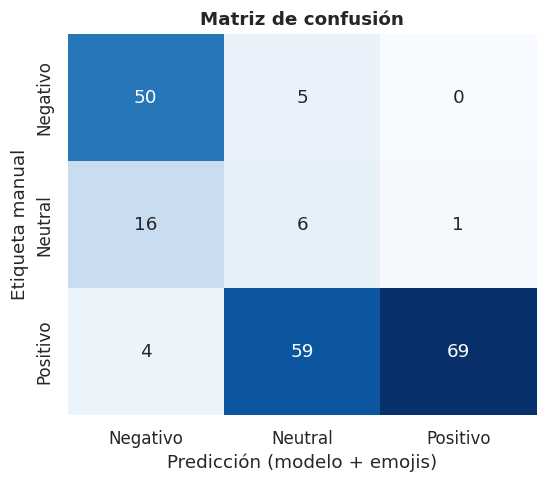

In [ ]:
CLASIFICADORES = {"Estrellas (referencia)": "grupo_estrellas",
                  "Modelo": "sentimiento_modelo",
                  "Modelo + emojis": "sentimiento"}

# Peso real de cada estrato de la muestra (la muestra se tomó por 'sentimiento')
peso_estrato = df["sentimiento"].value_counts(normalize=True)

def evaluar(columna):
    """Precisión por clase, exactitud ponderada por estrato y F1 macro frente a la etiqueta manual."""
    reporte = classification_report(val["etiqueta_manual"], val[columna], labels=ORDEN_SENTIMIENTO,
                                    output_dict=True, zero_division=0)
    precision = {f"precision_{c}": reporte[c]["precision"] * 100 for c in ORDEN_SENTIMIENTO}
    # Exactitud dentro de cada estrato, ponderada por su peso en las 34.328 reseñas
    exactitud_estrato = (val[columna] == val["etiqueta_manual"]).groupby(val["sentimiento"]).mean() * 100
    return {**precision,
            "exactitud_ponderada": (exactitud_estrato * peso_estrato).sum(),
            "f1_macro": reporte["macro avg"]["f1-score"] * 100}

comparacion = pd.DataFrame({nombre: evaluar(col) for nombre, col in CLASIFICADORES.items()}).T.round(1)
display(comparacion)

# Matriz de confusión del clasificador final (filas = etiqueta manual, columnas = predicción)
matriz = confusion_matrix(val["etiqueta_manual"], val["sentimiento"], labels=ORDEN_SENTIMIENTO)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap=CMAP_SECUENCIAL, cbar=False,
            xticklabels=ORDEN_SENTIMIENTO, yticklabels=ORDEN_SENTIMIENTO, ax=ax)
ax.set_xlabel("Predicción (modelo + emojis)")
ax.set_ylabel("Etiqueta manual")
ax.set_title("Matriz de confusión")
ax.grid(False)
guardar_figura(fig, "matriz_confusion", modulo=6)
plt.show()

**Nota:** la muestra se estratificó por la clase del modelo, no por estrellas. Por eso la fila de estrellas es solo una referencia aproximada.

## 6.6 - Ejemplos de aciertos y errores

In [ ]:
pd.set_option("display.max_colwidth", 200)
COLUMNAS_EJ = ["texto", "calificacion", "etiqueta_manual", "sentimiento"]
aciertos = val[val["etiqueta_manual"] == val["sentimiento"]]
errores = val[val["etiqueta_manual"] != val["sentimiento"]]
print(f"Aciertos: {len(aciertos)} | Errores: {len(errores)}")

# 2 aciertos por clase
print("\n=== Aciertos ===")
display(aciertos.groupby("sentimiento").head(2)[COLUMNAS_EJ])

# Tipos de error más frecuentes (manual -> predicción) y 3 ejemplos de cada uno de los 3 principales
tipos_error = errores.groupby(["etiqueta_manual", "sentimiento"]).size().sort_values(ascending=False)
print("\n=== Tipos de error (manual -> predicción) ===")
print(tipos_error)
for (manual, pred) in tipos_error.index[:3]:
    print(f"\n--- Manual: {manual} | Predicción: {pred} ---")
    display(errores[(errores["etiqueta_manual"] == manual) & (errores["sentimiento"] == pred)].head(3)[COLUMNAS_EJ])

Aciertos: 125 | Errores: 85

=== Aciertos ===


,texto,calificacion,etiqueta_manual,sentimiento
id_comentario,,,,
ffc07d8d-0098-4c76-a6dc-c7c80fb8e678,Al momento de abrir mi cuenta de nequi me pide los datos de la cédula los pongo correctamente y me sale un mensaje que ya tengo cédula de ciudadanía y no me deja seguir adelante con las fotos a la...,1,Negativo,Negativo
d43e995b-629e-4a10-a47b-13fdbe777e1c,muy buena aplicación para pagos y demás ☺️,4,Positivo,Positivo
cfb848b2-8a96-4e88-9787-f0911f1fd5e1,exelente,5,Positivo,Positivo
5fa87017-7418-4083-bf9b-49e7e0c61767,que demora para ingresar a poner plata en la tarjeta y para salir peor,2,Negativo,Negativo
1b8f50a2-694a-442f-989a-6cd697a3ee63,"la aplicación a veces no quiere abrir, pero uno puede pagar tranquilamente mientras tenga buena señal",5,Neutral,Neutral
fc78999f-7fd8-40af-9ac9-00572bbe1720,nesesito llamar a un asesor de nequi,1,Neutral,Neutral



=== Tipos de error (manual -> predicción) ===
etiqueta_manual  sentimiento
Positivo         Neutral        59
Neutral          Negativo       16
Negativo         Neutral         5
Positivo         Negativo        4
Neutral          Positivo        1
dtype: int64

--- Manual: Positivo | Predicción: Neutral ---


,texto,calificacion,etiqueta_manual,sentimiento
id_comentario,,,,
ca822000-8127-483a-9745-902442e1897f,excelente,5,Positivo,Neutral
c53db1d6-0e1f-4bd5-81e0-982482ba6b98,bueno,5,Positivo,Neutral
d724ff0f-f359-4feb-8d3a-778c8b3a474b,excelente,5,Positivo,Neutral



--- Manual: Neutral | Predicción: Negativo ---


,texto,calificacion,etiqueta_manual,sentimiento
id_comentario,,,,
13551316-69d6-4887-8b14-64d66ebe95b1,lo único que no me gusta es que es muy complicado para préstamos,5,Neutral,Negativo
4ea0c8dc-73bb-4cc3-b4ac-318001cf8399,no están llegando las notificaciones al recibir transferencia,4,Neutral,Negativo
349707b0-72fe-4bca-9577-f334733128f4,"muy mala aplicación, siempre está en 0",1,Neutral,Negativo



--- Manual: Negativo | Predicción: Neutral ---


,texto,calificacion,etiqueta_manual,sentimiento
id_comentario,,,,
ddda24de-f027-447a-b180-d73c6b0b0784,"es una app muy buena,Pero desde la última actualización,deje de recibir las notificaciones cuando hacen algún envío .. y para mí es muy importante la notificación cuando una recibe el dinero.. oja...",5,Negativo,Neutral
0ab7cb2f-e0e4-4b3e-bd39-e40c571bdb4f,"cuando quieran arreglen lo de abrir rápido, no? tómese su tiempo",1,Negativo,Neutral
48bb5a7e-b3d3-405d-8912-75eba5fbef7b,la verdad esque tiene que mejorar la parte que cuando se te olvida la contraseña con otras cosas y también facilitar a los clientes cuando lo descargue se le facilite,1,Negativo,Neutral


## 6.7 — Ajuste: desempate de la clase Neutral
**Error principal encontrado:** la mayoría de las reseñas que el modelo clasifica como Neutral son, en realidad, positivas (elogios cortos o factuales que el modelo no reconoce).

**Regla de ajuste:** si el modelo dice Neutral pero asigna **más probabilidad a positivo que a negativo**, la reseña pasa a Positivo.
- Usa solo información del propio modelo (sus probabilidades). **No usa las estrellas**, que se reservan para validar.
- No tiene umbrales ajustados a mano: compara dos probabilidades.
- Es conservadora: no convierte neutrales en negativos, porque ese error fue poco frecuente.

**Riesgo:** la regla se definió mirando la misma muestra con la que se evalúa (riesgo de sobreajuste). Para controlarlo, se confirma con una **muestra nueva** (6.7b).

El resultado queda en una columna nueva, `sentimiento_final`, que usan los módulos siguientes. `sentimiento` (modelo + emojis) no se modifica.

In [ ]:
# Regla: Neutral con más probabilidad positiva que negativa -> Positivo
regla_desempate = (df["sentimiento"] == "Neutral") & (df["p_pos"] > df["p_neg"])
df["sentimiento_final"] = np.where(regla_desempate, "Positivo", df["sentimiento"])
df["ajuste_desempate"] = regla_desempate.astype(int)

print(f"Reseñas reclasificadas: {regla_desempate.sum():,} ({regla_desempate.mean():.1%})")
print(df["sentimiento_final"].value_counts().reindex(ORDEN_SENTIMIENTO))

# Re-evaluar los clasificadores con la muestra manual, incluido el ajuste
val["sentimiento_final"] = val.index.map(df.set_index("id_comentario")["sentimiento_final"])
CLASIFICADORES["Modelo + emojis + desempate"] = "sentimiento_final"
comparacion = pd.DataFrame({nombre: evaluar(col) for nombre, col in CLASIFICADORES.items()}).T.round(1)
comparacion

Reseñas reclasificadas: 6,296 (18.3%)
sentimiento_final
Negativo     9807
Neutral      4922
Positivo    19599
Name: count, dtype: int64


,precision_Negativo,precision_Neutral,precision_Positivo,exactitud_ponderada,f1_macro
Estrellas (referencia),76.7,33.3,88.2,84.8,61.9
Modelo,71.4,8.5,98.6,60.9,53.5
Modelo + emojis,71.4,8.6,98.6,61.4,53.7
Modelo + emojis + desempate,71.4,11.1,93.8,77.3,59.5


### 6.7b — Muestra de confirmación
Muestra nueva de 50 reseñas **reclasificadas por la regla**, que no estaban en la primera muestra. Se etiquetan a ciegas con los mismos criterios de 6.2. Si la mayoría resulta positiva, la regla se confirma con datos que no se usaron para crearla.

In [ ]:
ARCHIVO_CONFIRMACION = DIR_SALIDAS / "06_muestra_confirmacion.xlsx"
ARCHIVO_CONFIRMACION_ETIQ = DIR_SALIDAS / "06_muestra_confirmacion_etiquetada.xlsx"

# Solo reseñas reclasificadas que no estaban en la primera muestra
candidatas = df[(df["ajuste_desempate"] == 1) & (~df["id_comentario"].isin(val.index))]
confirmacion = candidatas.sample(n=50, random_state=SEMILLA + 1)

if not ARCHIVO_CONFIRMACION.exists():
    (confirmacion[["id_comentario", "texto"]]
       .assign(etiqueta_manual="", nota="")
       .to_excel(ARCHIVO_CONFIRMACION, index=False))
    print("Muestra de confirmación exportada:", ARCHIVO_CONFIRMACION)
else:
    print("La muestra de confirmación ya existe; no se sobrescribe.")

Muestra de confirmación exportada: /content/drive/MyDrive/Colab Notebooks/No supervisado/Workshops/Final - Reseñas Usuarios Nequi/salidas/06_muestra_confirmacion.xlsx


### Pausa — Etiquetado manual
1. Abrir outputs/06_muestra_confirmacion.xlsx (en Excel o Google Sheets).
2. En etiqueta_manual, escribe solo Positivo, Neutral o Negativo.
3. Seguir los criterios de la 6.2 y usar colummna "nota" para los casos dudosos.
4. Guardar el archivo con otro nombre: 06_muestra_confirmacion_etiquetada.xlsx, en la misma carpeta "salidas".

## 6.7c - Resultado

In [ ]:
conf = pd.read_excel(ARCHIVO_CONFIRMACION_ETIQ)
conf["etiqueta_manual"] = conf["etiqueta_manual"].astype(str).str.strip().str.capitalize()
assert conf["etiqueta_manual"].isin(ORDEN_SENTIMIENTO).all(), "Hay etiquetas inválidas o vacías"

print(f"Precisión de la regla en la muestra nueva: {(conf['etiqueta_manual'] == 'Positivo').mean():.1%} (n = {len(conf)})")
conf["etiqueta_manual"].value_counts().reindex(ORDEN_SENTIMIENTO, fill_value=0)

Precisión de la regla en la muestra nueva: 92.0% (n = 50)


,count
etiqueta_manual,
Negativo,3
Neutral,1
Positivo,46


## 6.8 — Sesgos y limitaciones del método
| Limitación | Efecto | Cómo se manejó |
|---|---|---|
| El modelo fue entrenado con tuits, no con reseñas de apps | No reconoce elogios cortos o factuales ("sirve para pagar") y los marca como neutrales | Regla de desempate (6.7) |
| Sarcasmo e ironía | "cuando quieran arreglen lo de abrir rápido, no? tómese su tiempo" se clasificó como Neutral | Ejemplo real encontrado en la muestra; queda como limitación |
| Un solo criterio humano | Algunas etiquetas manuales contradicen los criterios de 6.2 (ej. "no están llegando las notificaciones…" marcado como Neutral). La precisión de Negativo (71,4 %) es probablemente un piso | Se declara; no se corrigieron solo los desacuerdos con el modelo, porque eso sesgaría la evaluación a su favor |
| Preguntas y reportes sin queja explícita | Algunos se clasifican como negativos aunque el usuario no se queja | Se declara; la precisión de Negativo es la referencia de confianza |
| Un solo criterio humano | La etiqueta manual también puede tener sesgo | Criterios escritos (6.2) y revisión ciega |
| Muestra estratificada por clase predicha | Permite medir precisión por clase, pero no la cobertura real de cada clase | Exactitud ponderada por estrato |
| Regla definida con la misma muestra | Riesgo de sobreajuste | Muestra de confirmación independiente (6.7b) |
| Pocos emojis en la base | La capa de emojis tiene efecto pequeño | Se reporta su efecto real |
| Las estrellas no son "la verdad" | Califican la app en general; el texto describe una experiencia concreta | Se usan solo como referencia, nunca para clasificar |

## 6.9 — **Hallazgos – Validación**
- **Muestra:** 210 reseñas (70 por clase), etiquetadas a ciegas con criterios escritos, más una muestra de confirmación independiente de 50 reseñas.
- **Positivo es muy confiable:** cuando el modelo dice Positivo, acierta el 98,6 % de las veces.
- **Negativo es aceptable:** 71,4 % de precisión. La mayoría de sus errores (16 de 70) son reseñas que el revisor marcó como neutrales; al revisarlas, varias son quejas según los criterios de 6.2 ("no están llegando las notificaciones al recibir transferencia"). Por eso la precisión real de Negativo probablemente es mayor.
- **Neutral era el punto débil:** solo 8,6 % de precisión. El 84 % de lo que el modelo llamó Neutral era, en realidad, positivo. La hipótesis inicial (quejas factuales leídas como neutrales) **no se confirmó**.
- **El modelo no reconoce elogios de una palabra:** reseñas como "excelente" o "bueno" fueron clasificadas como neutrales. Es el origen del error principal y la razón de la regla de desempate.
- **La capa de emojis casi no cambia la calidad** (precisión de Neutral de 8,5 % a 8,6 %): pocas reseñas tienen emojis.
- **Ajuste aplicado:** la regla de desempate reclasificó 6.296 reseñas (18,3 %) como positivas. La exactitud ponderada pasó de 61,4 % a 77,3 %; la precisión de Positivo bajó de 98,6 % a 93,8 %, pero sigue siendo alta. **En una muestra nueva de 50 reseñas reclasificadas, el 92,0 % era realmente positivo**, lo que confirma la regla con datos que no se usaron para crearla.
- **Neutral sigue siendo poco confiable** (11,1 % de precisión tras el ajuste): en los análisis siguientes se interpreta como "sin señal clara" y el foco se pone en Negativo vs. Positivo.
- **Sarcasmo:** se encontró un caso real ("cuando quieran arreglen lo de abrir rápido, no? tómese su tiempo") clasificado como Neutral. Es una limitación conocida de los modelos de sentimiento.
- **Implicación para el negocio:** la medición automática inicial subestimaba la satisfacción. Con el ajuste, la distribución final es 57,1 % positivas, 14,3 % neutrales y 28,6 % negativas.
- **Comparación con estrellas:** usar solo las estrellas alcanzaría una exactitud de 84,8 %, mayor que la del modelo ajustado (77,3 %). Las estrellas capturan bien la satisfacción general, pero no explican sus causas ni detectan a los usuarios satisfechos que reportan fallas. Por eso el texto es indispensable para el análisis de temas, y las estrellas se mantienen solo como referencia de validación.
- **Lección de pensamiento crítico:** sin la validación manual, el proyecto habría reportado un 38,8 % de reseñas positivas en lugar de 57,1 %. Una herramienta automática sin verificar puede llevar a conclusiones de negocio equivocadas.

# 7 — Clasificación temática
Cada reseña se clasifica en uno o varios temas con un **diccionario de palabras clave**.

**¿Por qué un diccionario?** Es explicable (se sabe por qué una reseña cae en un tema), reproducible y adecuado para un vocabulario repetitivo como el de estas reseñas.

**¿De dónde salen los temas?** De los grupos del clustering (módulo 4), los bigramas del EDA (3.4) y las categorías sugeridas por la rúbrica.

In [ ]:
# Raíces y frases por tema; \b = límite de palabra (evita que "rob" coincida con "problema")
TEMAS = {
    "Acceso a la cuenta":     r"\b(?:entrar|ingres\w*|iniciar sesion|contrasena|clave|bloque\w*|no (?:me )?(?:abre|habre|abrio))\b",
    "Registro y validación":  r"\b(?:(?:crear|abrir) (?:la |mi |una )?cuenta|registr\w*|reconocimiento|facial|rostro|foto|selfie|cedula|documento|valid\w*|verific\w*|menor(?:es)? de edad)\b",
    "Caídas y fallas":        r"\b(?:cae|caen|caida\w*|caido|falla\w*|error\w*|lent[oa]s?|no (?:funciona|sirve|carga)|se cierra|se pega|congela\w*|servidor|sin servicio)\b",
    "Notificaciones":         r"\bnotifica\w*",
    "Servicio al cliente":    r"\b(?:asesor\w*|soporte|chat|atencion|servicio al cliente|respuesta|responden|reclamo\w*|pqr\w*|solucion\w*|llamar)\b",
    "Transferencias y pagos": r"\b(?:transfer\w*|enviar|envio\w*|recibir|pag(?:o|os|ar|a|an|ue|uen)|pse|qr|factura\w*|recarg\w*|retir\w*|cajero\w*|corresponsal\w*|tarjeta\w*)\b",
    "Seguridad y fraude":     r"\b(?:segur\w*|rob\w*|estaf\w*|fraude\w*|hacke\w*|suplant\w*|ladron\w*)\b",
    "Costos y cobros":        r"(?:\b(?:cobr\w*|comision\w*|cuota\w*|interes(?:es)?|costo\w*|gratis|cuatro por mil|gmf)\b|4\s?x\s?1000|4\s?x\s?mil)",
    "Préstamos y crédito":    r"\b(?:prestamo\w*|credito\w*|cupo|salvavidas|propulsor)\b",
    "Facilidad de uso":       r"\b(?:facil\w*|practic\w*|sencill\w*|rapid\w*|comod\w*|util|intuitiv\w*)\b",
    "Actualizaciones":        r"\b(?:actualiz\w*|version\w*)\b",
    "Competidores":           r"\b(?:daviplata|bancolombia|nubank|movii|lulo|otros bancos|otras apps|otras aplicaciones)\b",
}
LISTA_TEMAS = list(TEMAS)

# Se busca sobre texto en minúsculas y sin tildes, conservando números ("4x1000")
texto_temas = df["texto_modelo"].str.lower().str.translate(TILDES)
for tema, patron in TEMAS.items():
    df[tema] = texto_temas.str.contains(patron).astype(int)   # 1 = la reseña menciona el tema
df["n_temas"] = df[LISTA_TEMAS].sum(axis=1)

## 7.2 — Frecuencia y cobertura

Cobertura total: 35.9% | en reseñas de 4+ palabras: 65.1%
Reseñas con más de un tema: 12.3%


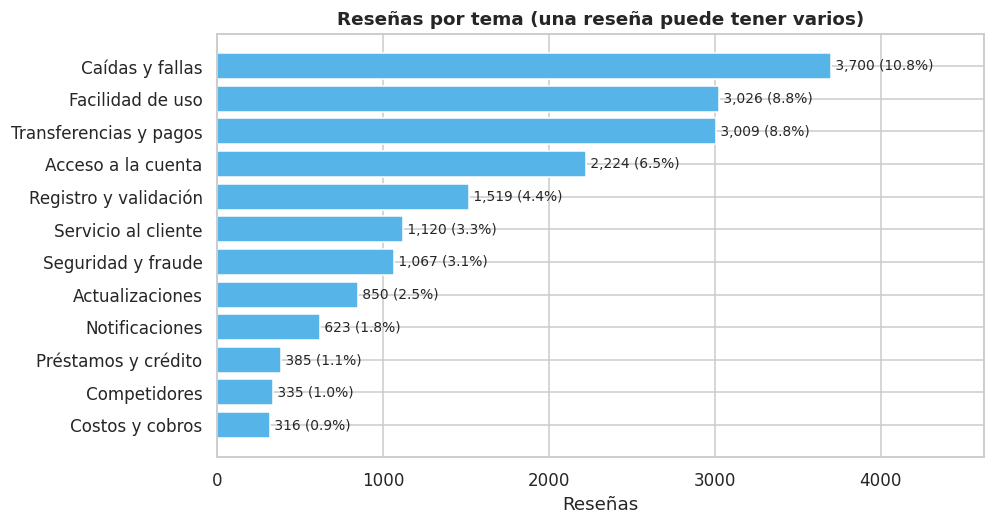

In [ ]:
larga = df["flag_corta"] == 0
print(f"Cobertura total: {(df['n_temas'] > 0).mean():.1%} | en reseñas de 4+ palabras: {(df.loc[larga, 'n_temas'] > 0).mean():.1%}")
print(f"Reseñas con más de un tema: {(df['n_temas'] > 1).mean():.1%}")

frecuencia = df[LISTA_TEMAS].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(frecuencia.index, frecuencia.values, color=COLOR_BASE)
for i, n in enumerate(frecuencia):
    ax.text(n, i, f" {n:,} ({n / len(df):.1%})", va="center", fontsize=9)
ax.set_title("Reseñas por tema (una reseña puede tener varios)")
ax.set_xlabel("Reseñas")
ax.set_xlim(0, frecuencia.max() * 1.25)
guardar_figura(fig, "frecuencia_temas", modulo=7)
plt.show()

## 7.3 — Contraste con los clusters
Qué % de cada cluster menciona cada tema. Si el diccionario es coherente, cada cluster debe concentrarse en pocos temas.

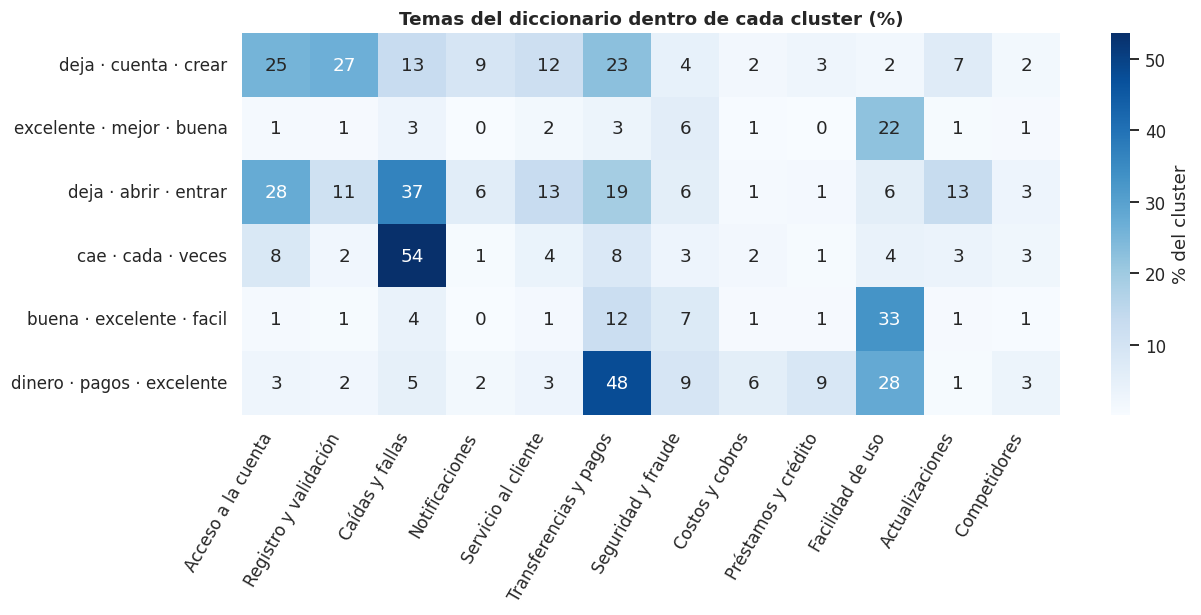

In [ ]:
# % de reseñas de cada cluster que mencionan cada tema (solo reseñas con cluster)
contraste = (df[df["cluster_nombre"] != "Sin cluster (corta)"]
               .groupby("cluster_nombre")[LISTA_TEMAS].mean().mul(100)
               .reindex(ORDEN_CLUSTER))

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(contraste, annot=True, fmt=".0f", cmap=CMAP_SECUENCIAL, cbar_kws={"label": "% del cluster"}, ax=ax)
ax.set_title("Temas del diccionario dentro de cada cluster (%)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
plt.xticks(rotation=60, ha="right")
guardar_figura(fig, "contraste_clusters_temas", modulo=7)
plt.show()

## 7.4 — **Hallazgos – Temas**
- **Cobertura:** el diccionario asigna tema al 65,1 % de las reseñas con 4+ palabras (35,9 % del total; las cortas suelen ser elogios sin tema). El 12,3 % menciona más de un tema.
- **Temas más mencionados:** Caídas y fallas (3.700; 10,8 %), Facilidad de uso (3.026; 8,8 %), Transferencias y pagos (3.009; 8,8 %) y Acceso a la cuenta (2.224; 6,5 %). Costos y cobros es el menos mencionado (316; 0,9 %): el precio no es un problema para los usuarios.
- **El diccionario y el clustering coinciden:**
  - "cae · cada · veces" → 54 % menciona Caídas y fallas.
  - "deja · abrir · entrar" → Caídas (37 %), Acceso (28 %) y Actualizaciones (13 %): la app deja de abrir, en parte después de actualizarse.
  - "deja · cuenta · crear" → Registro (27 %), Acceso (25 %) y Transferencias (23 %).
  - "dinero · pagos · excelente" → Transferencias y pagos (48 %) y Facilidad (28 %).
  - "buena · excelente · facil" → Facilidad de uso (33 %).
  - "excelente · mejor · buena" → casi sin temas específicos: es elogio general.
- **Validación cruzada:** dos métodos independientes (uno sin reglas y otro con reglas) llegan a los mismos temas, lo que da confianza en la clasificación.
- **Limitación:** las palabras clave no captan sinónimos no previstos ni el contexto ("seguro" puede ser elogio o queja); por eso el sentimiento se cruza con los temas en el módulo 8.

# 8 — Cruce entre sentimiento y temas
Pasa de describir a **priorizar**: qué temas concentran las quejas, cuáles generan satisfacción y dónde actuar primero. Se usa `sentimiento_final` (módulo 6).

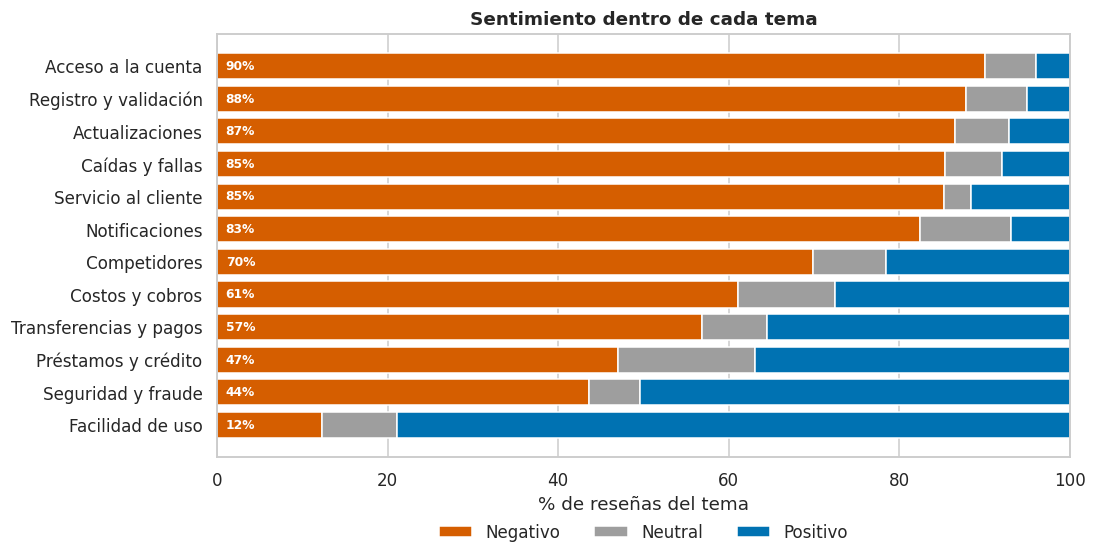

sentimiento_final,Negativo,Neutral,Positivo,reseñas
Facilidad de uso,12.3,8.8,78.8,3026
Seguridad y fraude,43.7,5.9,50.4,1067
Préstamos y crédito,47.0,16.1,36.9,385
Transferencias y pagos,56.9,7.5,35.5,3009
Costos y cobros,61.1,11.4,27.5,316
Competidores,69.9,8.7,21.5,335
Notificaciones,82.5,10.6,6.9,623
Servicio al cliente,85.3,3.1,11.6,1120
Caídas y fallas,85.4,6.7,7.9,3700
Actualizaciones,86.6,6.4,7.1,850


In [ ]:
# % de cada sentimiento dentro de cada tema (filas suman 100)
sent_tema = (pd.DataFrame({t: df.loc[df[t] == 1, "sentimiento_final"].value_counts(normalize=True) for t in LISTA_TEMAS})
               .T.reindex(columns=ORDEN_SENTIMIENTO).fillna(0).mul(100))
sent_tema["reseñas"] = df[LISTA_TEMAS].sum()
sent_tema = sent_tema.sort_values("Negativo")

# Barras apiladas: naranja = negativo, gris = neutral, azul = positivo
fig, ax = plt.subplots(figsize=(10, 5))
izquierda = np.zeros(len(sent_tema))
for s in ORDEN_SENTIMIENTO:
    ax.barh(sent_tema.index, sent_tema[s], left=izquierda, color=COLORES_SENTIMIENTO[s], label=s)
    izquierda += sent_tema[s].values
for i, neg in enumerate(sent_tema["Negativo"]):
    ax.text(1, i, f"{neg:.0f}%", va="center", color="white", fontsize=8, fontweight="bold")
ax.set_xlim(0, 100)
ax.set_xlabel("% de reseñas del tema")
ax.set_title("Sentimiento dentro de cada tema")
ax.legend(ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12), loc="upper center")
guardar_figura(fig, "sentimiento_por_tema", modulo=8)
plt.show()

sent_tema.round(1)

## 8.2 — Mapa de prioridad
- **Eje x:** cuántas reseñas mencionan el tema (alcance del problema).
- **Eje y:** % de reseñas negativas (gravedad).
- **Arriba a la derecha:** temas grandes y muy negativos -> **arreglar primero**.
- Las líneas punteadas marcan el volumen mediano y el % negativo general.

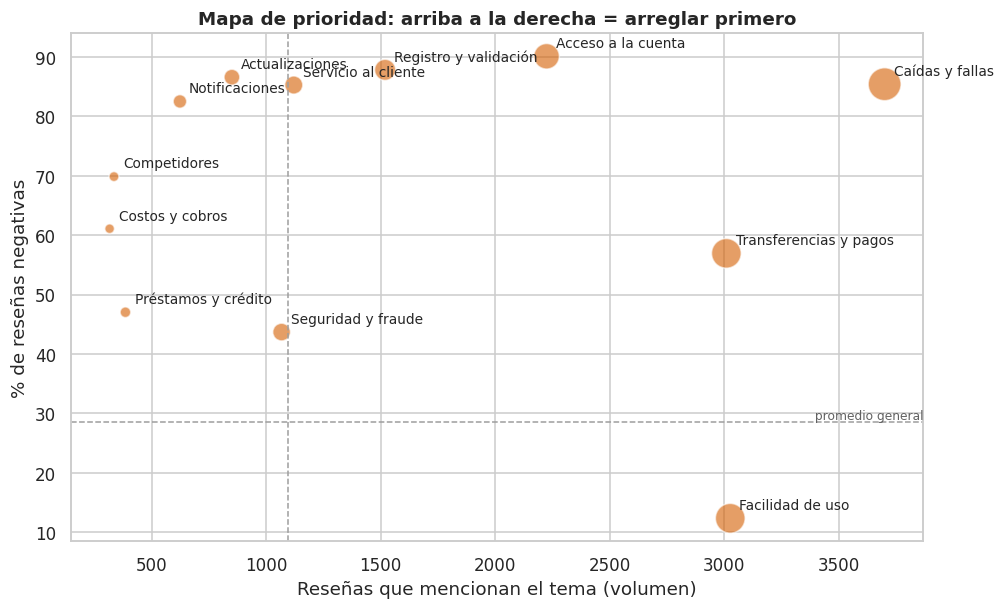

In [ ]:
pct_neg_global = (df["sentimiento_final"] == "Negativo").mean() * 100
volumen_mediano = sent_tema["reseñas"].median()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sent_tema["reseñas"], sent_tema["Negativo"], s=sent_tema["reseñas"] / 8,
           color=COLORES_SENTIMIENTO["Negativo"], alpha=0.6, edgecolor="white")
for tema, fila in sent_tema.iterrows():
    ax.annotate(tema, (fila["reseñas"], fila["Negativo"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.axhline(pct_neg_global, color="#9E9E9E", ls="--", lw=1)
ax.axvline(volumen_mediano, color="#9E9E9E", ls="--", lw=1)
ax.text(ax.get_xlim()[1], pct_neg_global, " promedio general", va="bottom", ha="right", fontsize=8, color="#616161")
ax.set_xlabel("Reseñas que mencionan el tema (volumen)")
ax.set_ylabel("% de reseñas negativas")
ax.set_title("Mapa de prioridad: arriba a la derecha = arreglar primero")
guardar_figura(fig, "mapa_prioridad", modulo=8)
plt.show()

## 8.3 — Temas de riesgo y lealtad
Qué temas aparecen en las reseñas con riesgo reputacional, intención de abandono y recomendación.

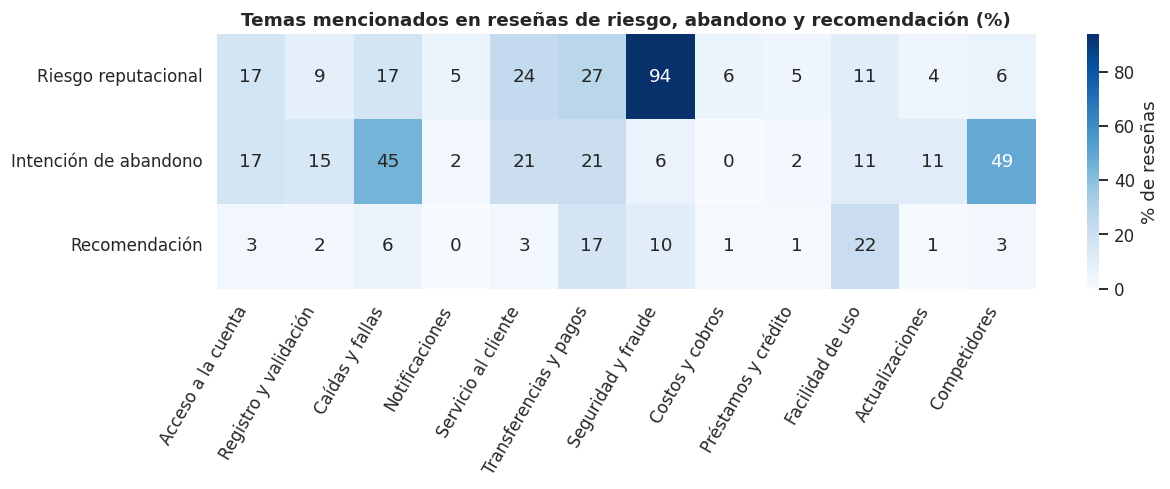

In [ ]:
ETIQUETAS_CLAVE = {"riesgo_reputacional": "Riesgo reputacional",
                   "intencion_abandono": "Intención de abandono",
                   "recomendacion": "Recomendación"}
temas_etiqueta = pd.DataFrame({nombre: df.loc[df[col] == 1, LISTA_TEMAS].mean() * 100
                               for col, nombre in ETIQUETAS_CLAVE.items()}).T

fig, ax = plt.subplots(figsize=(12, 3))
sns.heatmap(temas_etiqueta, annot=True, fmt=".0f", cmap=CMAP_SECUENCIAL, cbar_kws={"label": "% de reseñas"}, ax=ax)
ax.set_title("Temas mencionados en reseñas de riesgo, abandono y recomendación (%)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
plt.xticks(rotation=60, ha="right")
guardar_figura(fig, "temas_por_etiqueta", modulo=8)
plt.show()

## 8.4 — Evolución mensual de los temas negativos
Los 3 temas con más reseñas negativas, como % de todas las reseñas del mes. Muestra qué tema explicó la crisis de diciembre de 2025.

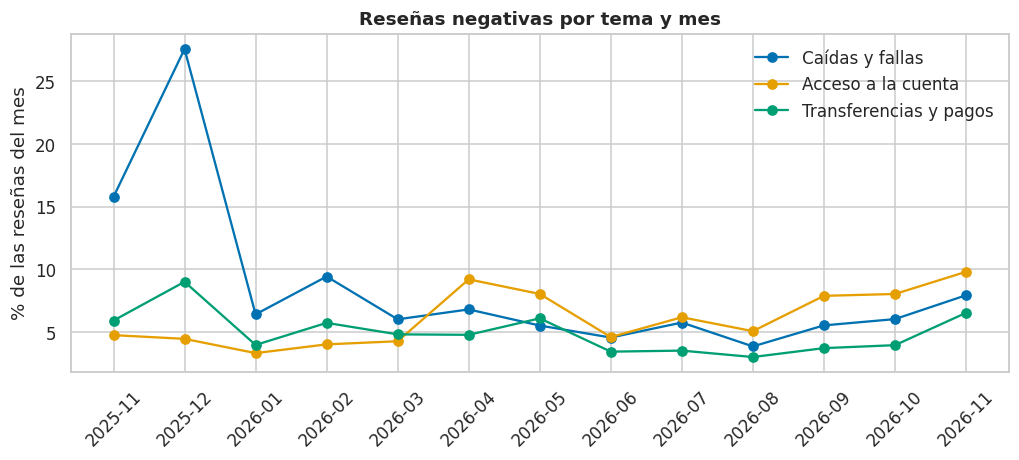

,Caídas y fallas,Acceso a la cuenta,Transferencias y pagos
mes,,,
2025-11,15.8,4.8,5.9
2025-12,27.6,4.5,9.0
2026-01,6.4,3.3,4.0
2026-02,9.4,4.0,5.7
2026-03,6.0,4.3,4.8
2026-04,6.8,9.2,4.8
2026-05,5.5,8.1,6.1
2026-06,4.6,4.6,3.5
2026-07,5.8,6.2,3.5


In [ ]:
negativas = df[df["sentimiento_final"] == "Negativo"]
TOP_TEMAS_NEG = negativas[LISTA_TEMAS].sum().nlargest(3).index.tolist()

# % de las reseñas del mes que son negativas Y mencionan el tema
evolucion = negativas.groupby("mes")[TOP_TEMAS_NEG].sum().div(df.groupby("mes").size(), axis=0).mul(100)

fig, ax = plt.subplots(figsize=(11, 4))
for tema, color in zip(TOP_TEMAS_NEG, COLORES_CLUSTER):
    ax.plot(evolucion.index, evolucion[tema], marker="o", color=color, label=tema)
ax.set_ylabel("% de las reseñas del mes")
ax.set_title("Reseñas negativas por tema y mes")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
guardar_figura(fig, "evolucion_temas_negativos", modulo=8)
plt.show()

evolucion.round(1)

## 8.5 — Respuestas de Nequi
Tasa de respuesta por mes, tiempo de respuesta y uso de plantillas. El tiempo solo se calcula en reseñas no editadas (ver 2.7 - Respuestas de Nequi).

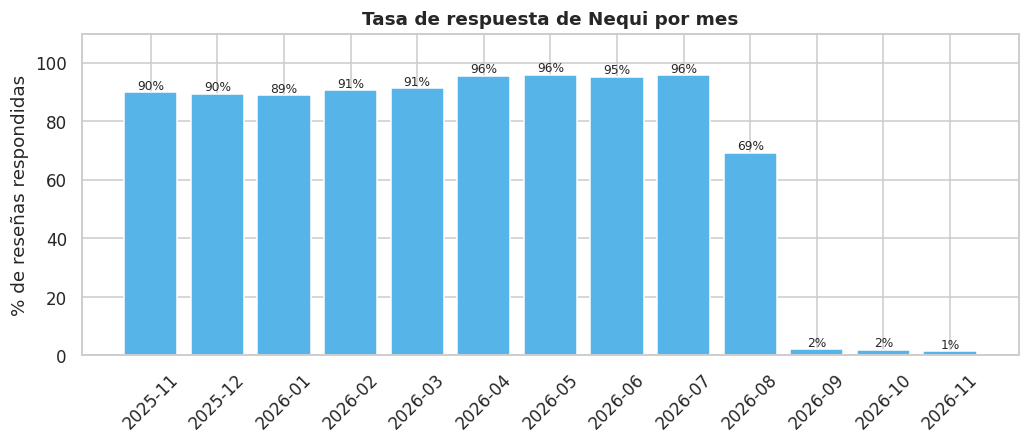

Respuestas: 26,032 | textos distintos: 18,282 | % repetidas: 35.2%
Mediana de respuesta: 7 minutos

Tasa de respuesta por sentimiento (%):
sentimiento_final
Negativo    78.1
Neutral     71.8
Positivo    75.7
Name: tiene_respuesta, dtype: float64


,count
respuesta_nequi,
"Lo mejor es que puedes ahorrar, pedir préstamos, comprar en nuestra tienda virtual y pagar tus facturas. Síguela usando para que puedas vivir la experiencia completa de ser parte de este parche ¡Te queremos! 💜",608
😎💜,589
💜,432
"Estamos siempre para ti😎, ¡Un abrazo!💜.",260
😉💜,210


,tasa_respuesta,mediana_minutos
mes,,
2025-11,89.9,11.4
2025-12,89.5,17.4
2026-01,89.0,5.8
2026-02,90.6,7.1
2026-03,91.3,8.1
2026-04,95.6,7.0
2026-05,95.9,5.0
2026-06,95.3,4.3
2026-07,95.8,6.0


In [ ]:
# Tasa de respuesta y mediana de minutos por mes
respuesta_mes = df.groupby("mes").agg(tasa_respuesta=("tiene_respuesta", "mean"),
                                       mediana_minutos=("horas_respuesta", lambda h: h.median() * 60))
respuesta_mes["tasa_respuesta"] *= 100

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(respuesta_mes.index, respuesta_mes["tasa_respuesta"], color=COLOR_BASE)
for i, v in enumerate(respuesta_mes["tasa_respuesta"]):
    ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, 110)
ax.set_ylabel("% de reseñas respondidas")
ax.set_title("Tasa de respuesta de Nequi por mes")
ax.tick_params(axis="x", rotation=45)
guardar_figura(fig, "tasa_respuesta_mensual", modulo=8)
plt.show()

# ¿Respuestas personalizadas o plantillas?
respuestas = df["respuesta_nequi"].dropna()
print(f"Respuestas: {len(respuestas):,} | textos distintos: {respuestas.nunique():,} | % repetidas: {respuestas.duplicated(keep=False).mean():.1%}")
print(f"Mediana de respuesta: {df['horas_respuesta'].median() * 60:.0f} minutos")
print("\nTasa de respuesta por sentimiento (%):")
print((df.groupby("sentimiento_final")["tiene_respuesta"].mean() * 100).round(1))
display(respuestas.value_counts().head(5))
respuesta_mes.round(1)

## 8.6 — **Hallazgos – Cruce sentimiento × tema**
- **¿Qué temas concentran más comentarios negativos?** Acceso a la cuenta (90,1 % negativas), Registro y validación (87,8 %), Actualizaciones (86,6 %), Caídas y fallas (85,4 %) y Servicio al cliente (85,3 %). Cuando un usuario menciona un tema concreto, casi siempre es para quejarse; los elogios suelen ser cortos y sin tema.
- **¿Qué atributos generan mayor sentimiento positivo?** La Facilidad de uso (78,8 % positivas; solo 12,3 % negativas) es la fortaleza clara de Nequi. Le siguen Seguridad (50,4 % positivas) y Préstamos y crédito (36,9 %).
- **¿Qué temas se asocian con recomendación (proxy de intención de uso)?** Facilidad de uso (22 % de las reseñas que recomiendan) y Transferencias y pagos (17 %). Los usuarios recomiendan Nequi por ser fácil y útil para mover dinero.
- **¿Qué categorías representan oportunidades de mejora? (mapa de prioridad)**
  - **Prioridad 1:** Caídas y fallas (3.700 reseñas; 85 % negativas) y Acceso a la cuenta (2.224; 90 %). Mucho volumen y mucha gravedad.
  - **Prioridad 2:** Registro y validación (1.519; 88 %) y Servicio al cliente (1.120; 85 %). Volumen medio, gravedad muy alta.
  - **Transferencias y pagos** (3.009; 57 %) es el uso principal de la app: es fortaleza y riesgo a la vez.
- **¿Qué temas pueden afectar la reputación?**
  - El 94 % de las reseñas con riesgo reputacional habla de Seguridad y fraude; también aparecen Transferencias (27 %) y Servicio al cliente (24 %): el usuario que sufre un fraude, además, no siente apoyo.
  - En las reseñas con intención de abandono dominan Competidores (49 %) y Caídas y fallas (45 %): **las caídas empujan a los usuarios hacia la competencia.**
- **Crisis de diciembre y tendencia actual:**
  - En dic-2025, las reseñas negativas sobre Caídas y fallas llegaron al 27,6 % de todas las reseñas del mes (frente a ~4-9 % el resto del año).
  - **Acceso a la cuenta es un problema creciente:** pasó de 3,3 % de las reseñas (ene-2026) a 9,8 % (nov-2026) y desde abril supera a Caídas en varios meses.
- **Respuestas de Nequi:**
  - Respondía ~90-96 % de las reseñas hasta julio de 2026, con una mediana de 7 minutos. Desde septiembre de 2026 responde ~2 %.
  - Las respuestas eran en gran parte plantillas: el 35,2 % de los textos se repite ("😎💜", "💜" o un mensaje promocional).
  - No priorizaba las quejas: respondía casi igual a negativas (78,1 %) que a positivas (75,7 %).
  - **Lectura:** Nequi pasó de responder rápido pero de forma genérica a dejar de responder. En ambos casos, el usuario con un problema no recibe ayuda real en este canal.

# 9 — Insights accionables
Cada insight conecta un hallazgo de los datos con su causa probable y su implicación para el negocio.

---

### Insight 1 — Las caídas en días de alta demanda empujan a los usuarios hacia la competencia
- **Hallazgo:** Caídas y fallas es el tema más mencionado (3.700 reseñas) y el 85,4 % es negativo.
- **Causa probable:** la plataforma no soporta los picos de uso. Los días críticos coinciden con quincenas y con la temporada decembrina; la prensa atribuyó las caídas de diciembre de 2025 a la migración a la nube.
- **Evidencia:** en dic-2025, las quejas por caídas fueron el 27,6 % de todas las reseñas del mes (vs. ~4-9 % el resto del año). El 06/12/2025 llegaron 767 reseñas (81,4 % negativas) y el 15/12/2025, día de quincena, 397 (77,1 %). En las reseñas con intención de abandono, el 45 % menciona caídas y el 49 % a un competidor.
- **Implicación:** la estabilidad no es solo un tema técnico, es **retención**. Cada caída en un día de pago es una invitación a probar Daviplata u otra billetera.

*Nota: la intención de abandono explícita aparece en solo 47 reseñas; el porcentaje es indicativo, no concluyente.*

### Insight 2 — Las actualizaciones están rompiendo lo básico: entrar a la cuenta y saber cuándo llega el dinero
- **Hallazgo:** Acceso a la cuenta es el tema más negativo (90,1 %) y el único con tendencia creciente: pasó de 3,3 % de las reseñas (ene-2026) a 9,8 % (nov-2026). Notificaciones (82,5 % negativas) y Actualizaciones (86,6 %) completan el patrón.
- **Causa probable:** cambios introducidos en las actualizaciones de la app. El cluster "deja · abrir · entrar" combina Caídas (37 %), Acceso (28 %) y Actualizaciones (13 %); las quejas de notificaciones suelen empezar con "desde la última actualización".
- **Evidencia:** "no deja" es el bigrama más frecuente en reseñas negativas (~1.300); desde abril de 2026, Acceso supera a Caídas en varios meses.
- **Implicación:** son las dos funciones más básicas de una billetera: **llegar al dinero y saber que llegó**. Si la tendencia sigue, será el principal problema de 2027.

### Insight 3 — El registro y la validación de identidad frenan la llegada de nuevos usuarios
- **Hallazgo:** Registro y validación tiene 87,8 % de reseñas negativas (1.519 reseñas).
- **Causa probable:** el proceso de verificación (reconocimiento facial, foto de la cédula) falla o rechaza a usuarios legítimos.
- **Evidencia:** "crear cuenta" y "reconocimiento facial" están entre los bigramas negativos más frecuentes; en el cluster "deja · cuenta · crear", el 27 % habla de registro.
- **Implicación:** cada registro fallido es un **cliente perdido antes de empezar**, que además deja una reseña negativa visible para futuros usuarios.

### Insight 4 — El usuario con un problema no encuentra ayuda, y lo dice en público
- **Hallazgo:** Servicio al cliente tiene 85,3 % de reseñas negativas, y los usuarios usan la tienda como canal de soporte (446 preguntas, 84,5 % negativas).
- **Causa probable:** los canales oficiales no resuelven, y la respuesta en la tienda era automática. Nequi respondía el ~90-96 % de las reseñas en minutos (mediana: 7), pero con plantillas (35,2 % de respuestas repetidas, como "😎💜") y sin priorizar quejas (78,1 % de respuesta a negativas vs. 75,7 % a positivas). Desde septiembre de 2026 responde solo ~2 %. El cambio coincide con la etapa de independencia de Bancolombia, pero estos datos no permiten confirmar la causa.
- **Evidencia adicional:** en las reseñas con riesgo reputacional (369), el 94 % habla de seguridad y fraude y el 24 % menciona el servicio al cliente: la víctima de un fraude, además, no se siente atendida.
- **Implicación:** las quejas sin respuesta quedan **públicas y sin resolver**, frente a millones de usuarios potenciales. En temas de fraude, esto erosiona la confianza, el activo central de una billetera digital.

### Insight 5 — La facilidad de uso es la ventaja competitiva que hay que proteger
- **Hallazgo:** Facilidad de uso es el tema más positivo (78,8 % positivas; solo 12,3 % negativas) y el principal motivo de recomendación (22 % de las reseñas que recomiendan).
- **Causa:** la propuesta de valor original de Nequi (simple, rápida, para todos) sigue siendo lo que el usuario valora.
- **Evidencia:** "excelente servicio", "fácil usar" y "fácil manejar" lideran los bigramas positivos; dos de los tres clusters positivos giran en torno a facilidad y pagos.
- **Implicación:** es el atributo que diferencia a Nequi. Cada actualización o control de seguridad nuevo debe cuidarlo: **las fallas de acceso (Insight 2) atacan justamente esta fortaleza**.

### Insight 6 — Las estrellas esconden a los usuarios leales que están acumulando fricción
- **Hallazgo:** el 7,9 % de las reseñas de 4-5 estrellas (~2.000) tiene texto negativo, y el texto es más crítico que la calificación: 72,9 % de reseñas de 4-5 estrellas frente a 57,1 % de texto positivo.
- **Causa:** las estrellas califican la app en general; el texto describe una experiencia concreta ("muy buena, pero se cae").
- **Evidencia:** "no deja", "no puedo" y "veces cae" aparecen también entre los bigramas de reseñas de 4-5 estrellas.
- **Implicación:** monitorear solo la calificación promedio da una falsa sensación de tranquilidad. Estos usuarios **todavía son leales, pero son los próximos detractores** si la fricción continúa.

# 10 — Estrategias de negocio y cierre

Cada estrategia responde a un insight (en orden de prioridad) e incluye la acción, el beneficio esperado y el indicador para medirla.

### Estrategia 1 — "Actualizaciones sin sorpresas" (Insight: acceso y notificaciones)
- **Acción:**
  1. Lanzar cada versión de forma escalonada (por ejemplo, 5 % → 20 % → 100 % de usuarios) y frenarla si suben las quejas de acceso o notificaciones.
  2. Pruebas obligatorias antes de cada lanzamiento sobre los dos flujos críticos: iniciar sesión y recibir notificaciones.
  3. Un botón visible de "no puedo entrar" con recuperación de acceso asistida.
- **Beneficio esperado:** detener el problema que más crece antes de que se vuelva el principal motivo de abandono en 2027, y proteger la confianza básica (llegar al dinero y saber que llegó).
- **KPI:** % de reseñas sobre acceso (9,8 % en nov-2026 → menos de 5 %); % de reseñas negativas en las 2 semanas posteriores a cada versión.

### Estrategia 2 — "Plan de quincena" (Insight: caídas en picos de demanda)
- **Acción:**
  1. Reforzar la capacidad de la plataforma en días de alta demanda (14-16 y 29-1 de cada mes, y todo diciembre).
  2. Aviso dentro de la app durante una caída, con causa y tiempo estimado de solución.
  3. Mensaje proactivo al terminar la caída, para cerrar el ciclo con el usuario.
- **Beneficio esperado:** evitar que una falla en día de pago empuje al usuario a probar otra billetera, y reducir el pico de reseñas negativas en crisis.
- **KPI:** disponibilidad de la app en días pico; % de reseñas negativas sobre caídas en diciembre (27,6 % en dic-2025 → menos de 10 %).

### Estrategia 3 — "Soporte que resuelve" (Insight: soporte y fraude)
- **Acción:**
  1. Retomar las respuestas en Google Play, priorizando reseñas de 1-2 estrellas y menciones de fraude.
  2. Respuestas personalizadas con número de caso, en lugar de plantillas ("😎💜").
  3. Canal prioritario de fraude, con atención humana.
  4. Al resolver un caso, invitar al usuario a actualizar su reseña.
- **Beneficio esperado:** convertir quejas públicas en casos resueltos visibles, y proteger la confianza frente al fraude.
- **KPI:** tasa de respuesta a reseñas de 1-2 estrellas (~2 % actual → más de 80 %); % de plantillas en las respuestas; reseñas editadas al alza.

### Estrategia 4 — "Registro sin fricción" (Insight: registro y validación)
- **Acción:**
  1. Guías en pantalla durante la captura (luz, encuadre, cédula completa) y mensajes de error que expliquen qué corregir.
  2. Una vía alternativa asistida cuando el reconocimiento facial falla varias veces.
- **Beneficio esperado:** recuperar usuarios que hoy abandonan antes de abrir su cuenta y reducir reseñas negativas de quienes aún no son clientes.
- **KPI:** tasa de registros completados; % de reseñas negativas sobre registro (87,8 % actual).

### Estrategia 5 — "Simple primero" (Insight: facilidad de uso)
- **Acción:**
  1. Centrar la comunicación de marca en la facilidad de uso, el atributo que más motiva la recomendación.
  2. Regla de diseño: ninguna función o control nuevo puede agregar pasos al flujo principal (enviar, recibir, pagar) sin justificación.
- **Beneficio esperado:** proteger la ventaja competitiva frente a otras billeteras y sostener la recomendación boca a boca.
- **KPI:** % de reseñas positivas sobre facilidad (78,8 % actual, mantener o subir); reseñas con recomendación.

### Estrategia 6 — "Escuchar el texto, no solo las estrellas" (Insight: leales con fricción)
- **Acción:**
  1. Tablero mensual de sentimiento por tema, construido con el pipeline de este proyecto.
  2. Alerta automática de "leales con fricción" (4-5 estrellas con texto negativo) para contactarlos antes de que se vuelvan detractores.
- **Beneficio esperado:** detectar crisis y problemas emergentes (como el aumento de quejas de acceso) meses antes de que bajen las estrellas.
- **KPI:** % de reseñas de 4-5 estrellas con texto negativo (7,9 % actual → menos de 5 %); días entre el inicio de un problema y su detección.

## 10.2 — Revisión de las hipótesis iniciales
| Área | Hipótesis (módulo 1) | ¿Se confirma? | Evidencia |
|---|---|---|---|
| Tecnología | Las caídas en días de alta demanda concentran las quejas | Sí | Caídas: 3.700 reseñas, 85,4 % negativas; pico de 27,6 % en dic-2025 |
| Servicio al cliente | Los canales de soporte no resuelven | Sí | 85,3 % negativas; respuestas con plantilla y caída de la tasa de respuesta a ~2 % |
| Producto | Algunas funciones generan más fricción que otras | Sí | Acceso (90,1 %) y Registro (87,8 %) son los temas más negativos |
| Comunicación | La falta de información durante caídas amplifica el daño | Parcial | Hay evidencia de falta de respuesta, pero no de la comunicación durante las caídas |
| Marca | Existen atributos valorados que pueden reforzar la lealtad | Sí | Facilidad de uso: 78,8 % positivas, principal motivo de recomendación |

## 10.3 - Exportación de resultados

In [ ]:
COLUMNAS_FINALES = (["id_comentario", "fecha", "calificacion", "texto", "sentimiento_final",
                     "puntaje_modelo", "cluster_nombre"] + ETIQUETAS_EXTRA + LISTA_TEMAS)

# Un solo Excel con una hoja por resultado clave
with pd.ExcelWriter(DIR_SALIDAS / "10_resultados_nequi.xlsx") as escritor:
    df[COLUMNAS_FINALES].to_excel(escritor, sheet_name="reseñas", index=False)
    sent_tema.round(1).to_excel(escritor, sheet_name="sentimiento_por_tema")
    perfil_cluster.to_excel(escritor, sheet_name="clusters")
    comparacion.to_excel(escritor, sheet_name="validacion")
    mensual.round(1).to_excel(escritor, sheet_name="evolucion_mensual")
    respuesta_mes.round(1).to_excel(escritor, sheet_name="respuestas_nequi")

print("Resultados guardados en:", DIR_SALIDAS / "10_resultados_nequi.xlsx")
print("Figuras guardadas:", len(list(DIR_FIGURAS.glob("*.png"))))

Exception ignored in: <function ZipFile.__del__ at 0x78d5ba8d00e0>
Traceback (most recent call last):
  File "/usr/lib/python3.13/zipfile/__init__.py", line 2042, in __del__
    self.close()
  File "/usr/lib/python3.13/zipfile/__init__.py", line 2059, in close
    self.fp.seek(self.start_dir)
ValueError: seek of closed file


Resultados guardados en: /content/drive/MyDrive/Colab Notebooks/No supervisado/Workshops/Final - Reseñas Usuarios Nequi/salidas/10_resultados_nequi.xlsx
Figuras guardadas: 19


## 10.4 - Verificación de integridad

In [ ]:
MD5_FINAL = md5_archivo(ARCHIVO_DATOS)
print("MD5 inicial:", MD5_ORIGINAL)
print("MD5 final:  ", MD5_FINAL)
assert MD5_FINAL == MD5_ORIGINAL, "¡El archivo original fue modificado!"
print("Archivo original intacto")

MD5 inicial: 5dad937bad0de1ed21d09ba9e8cb87e3
MD5 final:   5dad937bad0de1ed21d09ba9e8cb87e3
Archivo original intacto


## 10.5 — Resumen ejecutivo

**Pregunta de negocio:** ¿qué problemas dañan la experiencia de los usuarios de Nequi, cómo cambian en el tiempo y qué acciones priorizar para proteger su reputación en su nueva etapa independiente?

**Datos:** 34.328 reseñas de Google Play Colombia (nov-2025 a nov-2026), recolectadas con *web scraping*. Ninguna reseña fue eliminada en la limpieza.

| Indicador | Valor |
|---|---|
| Reseñas positivas / negativas (texto, validado) | 57,1 % / 28,6 % |
| Tema más negativo | Acceso a la cuenta (90,1 % negativas), y en aumento |
| Pico de crisis | Dic-2025: 27,6 % de las reseñas del mes fueron quejas por caídas |
| Tasa de respuesta de Nequi | ~95 % (jul-2026) → ~2 % (desde sep-2026) |

**Método:** modelo de sentimiento en español (`pysentimiento`) + capa de emojis, validado con 260 reseñas revisadas a mano (exactitud ponderada: 77,3 %); temas por diccionario, contrastados con clustering de embeddings (K-Means).

**Prioridades:**
1. **Acceso y actualizaciones:** el problema más negativo y el único que crece → lanzamientos escalonados y recuperación de acceso asistida.
2. **Caídas en picos:** el tema más mencionado y ligado al abandono → plan de capacidad para quincenas y diciembre.
3. **Soporte y fraude:** quejas públicas sin respuesta real → respuestas priorizadas y personalizadas.
4. **Registro:** barrera para nuevos clientes → guías de captura y validación alternativa.
5. **Facilidad de uso:** la fortaleza a proteger en cada cambio.
6. **Medición:** monitorear el texto, no solo las estrellas, para detectar a tiempo a los leales con fricción.

**Limitaciones:** solo usuarios de Android; reseñas autoseleccionadas; el modelo no reconoce elogios de una palabra (corregido con la regla de desempate, confirmada en una muestra nueva); el sarcasmo no se detecta; la intención de abandono explícita es poco frecuente (47 reseñas).